# Regulatory Policy and Market Parity in Formula 1

**Evaluating competitive balance before and after the cost cap**

**Team B05:** Adrian Marcell, Ashwin Pillanda Ravindra, Jenniffer Hierro Cruz, and Saleha Hassan Alvi  
**Analysis:** 2010–2025; 11 pre-cap seasons and 5 post-cap seasons  
**Source:** [F1DB](https://github.com/f1db/f1db), release `v2026.15.1`  
**Attribution:** F1DB contributors, [CC BY 4.0](https://github.com/f1db/f1db/blob/main/LICENSE); we filter, join, and aggregate the data.  
**Notebook:** `B05-F1-Cost-Cap.ipynb`; the automatic download requires internet access.

## Executive Summary

We compared constructor points shares from 2010–2025 to examine competitive balance before and after F1's 2021 cost cap.
Average top-two share fell from 54.72% to 52.14%, but the original Welch test was inconclusive (t = −1.215, p = 0.245).
The P4–P7 group gained share, from 24.71% to 26.16%, and more teams reached podiums, although the number of race-winning teams barely changed.
The Big Three comparison reverses when 2025 is excluded, and a shorter pre-cap baseline changes the CR2 result.
Across the whole field, the effective number of equal-share teams moved only from 4.83 to 4.92.
We recommend checking several competition measures before changing regulations, setting team benchmarks against relevant peers, and assessing emerging sponsorship contenders; five post-cap seasons and overlapping rule changes prevent us from isolating the cap's effect.

## 1. Introduction and Motivation

**Did limiting spending help more F1 teams compete near the front?**

In Formula 1, a team is also called a constructor. Each fields two drivers, whose points count toward the Constructors' Championship. The final standings measure performance across the season and not just who won the last race.

F1 introduced a \$145 million spending baseline in 2021, followed by \$140 million in 2022 and \$135 million from 2023. Adjustments and excluded costs mean these figures are not total team budgets.

Our earlier comparison found a small fall in the top teams' combined points share. This report asks which seasons and teams explain that change, and whether wins and podiums tell the same story. The findings matter to regulators reviewing the rules, teams choosing performance targets, and sponsors selecting partners.

**Takeaway.** A lower era average is a starting point. We also need to know who gained and whether the result lasts across different comparisons.

## 2. Business Question and Method

**What would a more balanced championship look like in the data?**

We divide each team's points by all constructor points that season. This puts different season totals on a common scale. Points share measures sporting results, not revenue, spending, or the speed gap between cars. **P1 means first place. P4–P7 means fourth through seventh in the final standings.**

| Measure | What it tells us | Calculation |
|---|---|---|
| Points share | One team's share of the season's points | Team points / all constructor points × 100 |
| CR2 | Concentration at the top | Combined share of official P1 and P2 |
| Midfield share | Points captured by the middle group | Combined share of official P4–P7 |
| Big Three share | Results of Ferrari, Mercedes, and Red Bull | Combined share of those three teams |
| Championship margin | Closeness between the first two teams | P1 share − P2 share, in percentage points |
| Effective equal-share constructors | Evenness across the field | 1 / sum of squared fractional shares |

The main comparison is **2010–2020 versus 2021–2025**: 11 seasons before the cap and 5 after it. We also compare against **2014–2020** and leave out individual post-cap years to check sensitivity. Each season has equal weight. The incomplete 2026 season is excluded.

The analysis uses cleaning, relational joins, grouping, descriptive statistics, and two-sided Welch tests with unequal variances. Differences and test statistics consistently use **post-cap minus pre-cap**. A season is one observation. Teams and races are not treated as independent extra seasons. Supporting tests are exploratory and unadjusted for multiple comparisons.

There is no machine learning or forecasting. Chart 15 explains its sum-of-squares measure with a simple example. CR2, midfield share, and Big Three share overlap, so they cannot be added as separate slices of a pie.

**Takeaway.** Concentration, changes in rank, and access to wins or podiums answer different parts of the balance question.

## 3. Data Preparation and Earlier Findings

### 3.1 Source and Download

**Can another reader reproduce the analysis from the same data?**

We download F1DB's CSV archive from GitHub and pin release `v2026.15.1`. The SHA-256 checksum acts as a file fingerprint, checked against GitHub's metadata. Setting the release override to `None` allows a future refresh, followed by a new run and review.

Constructor standings provide season points and official ranks. Constructor, season, and race tables support joins and coverage checks. Grand Prix results supply wins and podiums, and F1DB's chronology supports the team-name mapping.

In [1]:
# Standard libraries handle release discovery, download, archive validation, and hashing.
from datetime import datetime, timezone
import hashlib
import io
import json
import zipfile
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import sys
import matplotlib
import scipy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from IPython.display import Markdown, display

START_YEAR = 2010
END_YEAR = 2025  # Keep 2026 out of all annual comparisons; its season is incomplete.
RELEASE_TAG_OVERRIDE = "v2026.15.1"  # Fixed snapshot; use None only for a deliberate data refresh.
RELEASE_API_ROOT = "https://api.github.com/repos/f1db/f1db/releases"
ASSET_NAME = "f1db-csv.zip"

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

print(f"Python/pandas analysis initialized. Window: {START_YEAR}–{END_YEAR}.")
print(f"Versions: Python {sys.version.split()[0]}, pandas {pd.__version__}, NumPy {np.__version__}, Matplotlib {matplotlib.__version__}, SciPy {scipy.__version__}.")

Python/pandas analysis initialized. Window: 2010–2025.
Versions: Python 3.13.16, pandas 2.2.3, NumPy 2.1.3, Matplotlib 3.10.0, SciPy 1.16.3.


In [2]:
# Discover the latest stable release (or an explicitly pinned tag) and download its CSV bundle.
release_endpoint = (
    f"{RELEASE_API_ROOT}/tags/{RELEASE_TAG_OVERRIDE}"
    if RELEASE_TAG_OVERRIDE
    else f"{RELEASE_API_ROOT}/latest"
)
request_headers = {
    "User-Agent": "BA780-F1-Cost-Cap-Notebook/1.0",
    "Accept": "application/vnd.github+json",
}

try:
    with urlopen(Request(release_endpoint, headers=request_headers), timeout=30) as response:
        release = json.loads(response.read().decode("utf-8"))
except (HTTPError, URLError, TimeoutError) as exc:
    raise RuntimeError(
        "Could not reach the F1DB GitHub Releases endpoint. Check the notebook's internet access, "
        "then rerun this cell. No older local CSV is silently substituted."
    ) from exc

assets = [asset for asset in release.get("assets", []) if asset.get("name") == ASSET_NAME]
assert len(assets) == 1, f"Expected exactly one {ASSET_NAME!r} asset; found {len(assets)}."
asset = assets[0]
asset_url = asset["browser_download_url"]

try:
    with urlopen(Request(asset_url, headers={"User-Agent": request_headers["User-Agent"]}), timeout=90) as response:
        archive_bytes = response.read()
except (HTTPError, URLError, TimeoutError) as exc:
    raise RuntimeError(f"Could not download the F1DB release asset: {asset_url}") from exc

actual_sha256 = hashlib.sha256(archive_bytes).hexdigest()
expected_digest = asset.get("digest") or ""
if expected_digest.startswith("sha256:"):
    expected_sha256 = expected_digest.removeprefix("sha256:")
    assert actual_sha256 == expected_sha256, "Downloaded release checksum does not match GitHub metadata."
    checksum_status = "verified against GitHub SHA-256"
else:
    checksum_status = "computed locally (GitHub did not publish a digest field)"

print(f"F1DB release: {release.get('tag_name', 'tag unavailable')}")
print(f"Published: {release.get('published_at', 'date unavailable')}")
print(f"Asset: {ASSET_NAME} ({asset.get('size', len(archive_bytes)):,} bytes)")
print(f"SHA-256: {actual_sha256} ({checksum_status})")
print(f"Source: {asset_url}")
print(f"Retrieved UTC: {datetime.now(timezone.utc).isoformat(timespec='seconds')}")

required_files = {
    "constructors": "f1db-constructors.csv",
    "standings": "f1db-seasons-constructor-standings.csv",
    "seasons": "f1db-seasons.csv",
    "races": "f1db-races.csv",
    "race_results": "f1db-races-race-results.csv",
}
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    archive_names = archive.namelist()
    csv_members = {}
    for table_name, expected_filename in required_files.items():
        matches = [member for member in archive_names if member.rsplit("/", 1)[-1] == expected_filename]
        assert len(matches) == 1, f"Expected one {expected_filename!r} in the release; found {len(matches)}."
        csv_members[table_name] = matches[0]
    raw = {
        table_name: pd.read_csv(io.BytesIO(archive.read(member)), low_memory=False)
        for table_name, member in csv_members.items()
    }

source_inventory = pd.DataFrame([
    {"table": name, "file": required_files[name], "rows": len(frame), "columns": len(frame.columns)}
    for name, frame in raw.items()
])
# The inventory is displayed with the audit below.
assert len(archive_bytes) > 0, "The downloaded CSV archive is empty."

F1DB release: v2026.15.1
Published: 2026-09-27T09:57:43Z
Asset: f1db-csv.zip (4,486,820 bytes)
SHA-256: 56c42ec173ee25d88457acf2378cbfbdd3aafbf97724f0d4eafbe71ae4b1f133 (verified against GitHub SHA-256)
Source: https://github.com/f1db/f1db/releases/download/v2026.15.1/f1db-csv.zip
Retrieved UTC: 2026-10-19T20:19:25+00:00


**Takeaway.** The output identifies the release, checksum, and download time used for the saved results.

### 3.2 Source Audit and Cleaning

**Which missing values and duplicate records need attention?**

| Field or table | Issue | Action and reason |
|---|---|---|
| `year` | The source includes years outside the study | Keep 2010–2025 and check all 16 seasons |
| `points` | Missing points would invalidate shares | Check numeric values and nulls; stop if points are missing |
| `positionNumber` | Some entries have no official rank | Preserve blanks and use the official ranking |
| 2018 `force-india` | Two entries share a constructor-year key | Retain the ranked 52-point row and zero-point, unranked companion after checking the exception |
| Lookup tables | Joins could add rows or miss matches | Require unique keys, many-to-one joins, complete matches, and unchanged row counts |
| Race results | Some retirements lack a numeric position | Keep the records; use official positions to select wins and podiums |

The two Force India rows need different treatment from an accidental duplicate. The original 2018 entry forfeited its constructor points, and its replacement started from zero. We preserve the two F1DB rows and restore no forfeited points. **There are two rows in this duplicate-key group, but only one is the unranked, zero-point companion.** The audit field named `documented_constructor_year_companion_rows` counts both rows in the group.

Season totals already include sprints and championship adjustments. We use those official totals directly for points shares.

In [3]:
critical_columns = {
    "standings": ["year", "positionNumber", "constructorId", "points"],
    "constructors": ["id", "name"],
    "seasons": ["year"],
    "races": ["id", "year"],
    "race_results": ["raceId", "positionNumber", "constructorId"],
}
null_records = []
for table_name, columns in critical_columns.items():
    assert set(columns).issubset(raw[table_name].columns), f"Missing required columns in {table_name}."
    nulls = raw[table_name][columns].isna().sum()
    for column, count in nulls.items():
        null_records.append({"table": table_name, "column": column, "null_count": int(count)})
null_audit = pd.DataFrame(null_records)
raw_audit = source_inventory.assign(
    duplicate_rows_before=[int(raw[name].duplicated().sum()) for name in source_inventory["table"]]
).rename(columns={"rows": "rows_before", "columns": "columns_before"})
display(raw_audit)
display(null_audit.loc[null_audit["null_count"].gt(0)])
print(f"Audited {len(null_audit)} required fields; the table above shows fields with missing values.")
assert raw["standings"]["points"].notna().all(), "Missing championship points need investigation."

,table,file,rows_before,columns_before,duplicate_rows_before
0,constructors,f1db-constructors.csv,187,22,0
1,standings,f1db-seasons-constructor-standings.csv,721,8,0
2,seasons,f1db-seasons.csv,77,1,0
3,races,f1db-races.csv,1172,47,0
4,race_results,f1db-races-race-results.csv,27621,34,0


,table,column,null_count
1,standings,positionNumber,3
10,race_results,positionNumber,10923


Audited 12 required fields; the table above shows fields with missing values.


In [4]:

# Prepare just the fields required for analysis and preserve identifiers for relational joins.
standings = raw["standings"][critical_columns["standings"]].copy()
standings["year"] = pd.to_numeric(standings["year"], errors="raise")
standings["positionNumber"] = pd.to_numeric(standings["positionNumber"], errors="raise")
standings["points"] = pd.to_numeric(standings["points"], errors="raise")
standings["constructorId"] = standings["constructorId"].astype("string")

constructors = raw["constructors"][critical_columns["constructors"]].copy()
constructors = constructors.rename(columns={"id": "constructorId", "name": "constructorName"})
constructors["constructorId"] = constructors["constructorId"].astype("string")
assert constructors[["constructorId", "constructorName"]].notna().all().all(), "Constructor lookup has missing keys or names."
assert not constructors["constructorId"].duplicated().any(), "Constructor lookup IDs must be unique."

seasons = raw["seasons"][critical_columns["seasons"]].copy()
seasons["year"] = pd.to_numeric(seasons["year"], errors="raise")

# Keep complete seasons in the analysis window; exclude 2026.
standings = standings.loc[standings["year"].between(START_YEAR, END_YEAR)].copy()
assert set(standings["year"].astype(int).unique()) == set(range(START_YEAR, END_YEAR + 1)), \
    "The source does not contain every expected complete season from 2010 through 2025."
assert standings[["year", "constructorId", "points"]].notna().all().all(), \
    "A required season, constructor ID, or point value is null after filtering."

# A blank official rank is retained as a source value, never inferred from points.
unranked_count = int(standings["positionNumber"].isna().sum())
print(f"Constructor standings with no numeric positionNumber in scope: {unranked_count}")
assert standings["points"].ge(0).all(), "Negative constructor points require investigation."

# A standings row should be unique at constructor-season grain; report and assert, never deduplicate blindly.
duplicate_keys = standings.duplicated(["year", "constructorId"], keep=False)
duplicate_rows = standings.loc[duplicate_keys].copy()
print(f"Rows belonging to duplicated constructor-season keys: {len(duplicate_rows)}")
if not duplicate_rows.empty:
    assert set(zip(duplicate_rows["year"], duplicate_rows["constructorId"])) == {(2018, "force-india")}, \
        "An undocumented duplicate constructor-season key needs review."
    display(duplicate_rows[["year", "positionNumber", "constructorId", "points"]].sort_values(["year", "constructorId", "positionNumber"]))
    duplicate_groups = duplicate_rows.groupby(["year", "constructorId"]).agg(
        row_count=("constructorId", "size"),
        rows_with_official_rank=("positionNumber", "count"),
    )
    unranked_duplicate_rows = duplicate_rows.loc[duplicate_rows["positionNumber"].isna()]
    # Preserve the upstream extra row only when it is a zero-point, unranked companion to one ranked row.
    assert duplicate_groups["row_count"].eq(2).all(), "Unexpected multi-row constructor-season group; investigate before calculating shares."
    assert duplicate_groups["rows_with_official_rank"].eq(1).all(), "A duplicate constructor-season key has multiple ranked rows."
    assert unranked_duplicate_rows["points"].eq(0).all(), "An unranked duplicate has nonzero points; investigate before proceeding."
    print(f"Validated unranked zero-point companion rows retained: {len(unranked_duplicate_rows)}")
# No rows are dropped: all source points stay in the annual denominator.

row_count_before_joins = len(standings)
standings = standings.merge(
    constructors,
    on="constructorId",
    how="left",
    validate="many_to_one",
    indicator="constructor_join",
)
assert standings["constructor_join"].eq("both").all(), "A standings constructor has no constructor-name match."
standings = standings.drop(columns="constructor_join")

season_lookup = seasons[["year"]].copy()
assert season_lookup["year"].notna().all(), "Season lookup has a missing year."
assert not season_lookup["year"].duplicated().any(), "Season reference year must be unique."
standings = standings.merge(
    season_lookup,
    on="year",
    how="left",
    validate="many_to_one",
    indicator="season_join",
)
assert standings["season_join"].eq("both").all(), "A standings year has no season-reference match."
standings = standings.drop(columns="season_join")
assert len(standings) == row_count_before_joins, "A lookup join unexpectedly changed the standings row count."

# Official positionNumber is the tie-break-aware rank supplied by F1DB/FIA standings.
standings["positionNumber"] = standings["positionNumber"].astype("Int64")
standings["year"] = standings["year"].astype(int)
standings = standings.sort_values(["year", "positionNumber", "constructorId"]).reset_index(drop=True)

print(f"Rows preserved through validated many-to-one joins: {row_count_before_joins:,} → {len(standings):,}")
print(f"Filtered years: {standings['year'].min()}–{standings['year'].max()} ({standings['year'].nunique()} seasons)")
unranked_mask = standings["positionNumber"].isna()
if unranked_mask.any():
    print("Unranked rows retained in the points-share denominator:")
    display(standings.loc[unranked_mask, ["year", "constructorName", "points"]].sort_values(["year", "constructorName"]))
display(pd.DataFrame([{
    "stage": "After filtering and lookup joins", "rows_after": len(standings),
    "columns_after": len(standings.columns), "null_points_after": int(standings["points"].isna().sum()),
    "duplicate_full_rows_after": int(standings.duplicated().sum()),
    "documented_constructor_year_companion_rows": len(duplicate_rows),
}]))
display(standings.head(3))

Constructor standings with no numeric positionNumber in scope: 1
Rows belonging to duplicated constructor-season keys: 2


,year,positionNumber,constructorId,points
635,2018,7.0,force-india,52.0
639,2018,NaN,force-india,0.0


Validated unranked zero-point companion rows retained: 1
Rows preserved through validated many-to-one joins: 170 → 170
Filtered years: 2010–2025 (16 seasons)
Unranked rows retained in the points-share denominator:


,year,constructorName,points
99,2018,Force India,0.0


,stage,rows_after,columns_after,null_points_after,duplicate_full_rows_after,documented_constructor_year_companion_rows
0,After filtering and lookup joins,170,5,0,0,2


,year,positionNumber,constructorId,points,constructorName
0,2010,1,red-bull,498.0,Red Bull
1,2010,2,mclaren,454.0,McLaren
2,2010,3,ferrari,396.0,Ferrari


**Takeaway.** Filtering leaves 170 standings rows from 721 all-time records. The lookup joins retain all 170, including the one zero-point companion.

### 3.3 Coverage and Points Shares

**Do the race records and annual shares reconcile?**

We match results to the race schedule and check that every Grand Prix has one official winner. Team points are divided by each season's total, and the annual shares must sum to 100% within a small allowance for computer rounding.

In [5]:
# Reconcile each modern-season race result to a race year and verify one race winner per event.
races = raw["races"][critical_columns["races"]].copy()
races["id"] = races["id"].astype("string")
races["year"] = pd.to_numeric(races["year"], errors="raise")
race_lookup = races.rename(columns={"id": "raceId"})
race_lookup["raceId"] = race_lookup["raceId"].astype("string")
assert not race_lookup["raceId"].duplicated().any(), "Race IDs are not unique in the race lookup."

race_results = raw["race_results"][critical_columns["race_results"]].copy()
race_results["raceId"] = race_results["raceId"].astype("string")
race_results["constructorId"] = race_results["constructorId"].astype("string")
race_results["positionNumber"] = pd.to_numeric(race_results["positionNumber"], errors="raise")
race_audit = race_results.merge(
    race_lookup[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one",
    indicator="race_join",
)
assert race_audit["race_join"].eq("both").all(), "Some race-result rows do not match a race ID."
race_audit = race_audit.drop(columns="race_join")
race_audit = race_audit.loc[race_audit["year"].between(START_YEAR, END_YEAR)].copy()
race_audit["year"] = race_audit["year"].astype(int)

winner_rows = race_audit.loc[race_audit["positionNumber"].eq(1)]
winners_per_race = winner_rows.groupby(["year", "raceId"], as_index=False).size().rename(columns={"size": "p1_rows"})
expected_races = race_lookup.loc[race_lookup["year"].between(START_YEAR, END_YEAR)].copy()
assert set(race_audit["raceId"]) == set(expected_races["raceId"]), \
    "Race-result event coverage differs from the separate race schedule."
races_per_year = expected_races.groupby("year")["raceId"].nunique().rename("race_count")
winners_per_year = winners_per_race.groupby("year").agg(
    race_winners=("p1_rows", "sum"),
    events_with_one_p1=("p1_rows", lambda values: int(values.eq(1).sum())),
)
race_integrity = pd.concat([races_per_year, winners_per_year], axis=1).reset_index()
race_integrity["event_count_matches"] = race_integrity["race_count"].eq(race_integrity["race_winners"])
race_integrity["one_p1_per_event"] = race_integrity["events_with_one_p1"].eq(race_integrity["race_count"])
assert set(race_integrity["year"]) == set(range(START_YEAR, END_YEAR + 1)), "Race results do not cover all analysis seasons."
assert race_integrity["event_count_matches"].all(), "Race-result winner count does not match event count."
assert race_integrity["one_p1_per_event"].all(), "At least one event has zero or multiple P1 result rows."
display(race_integrity.head(3))
print(f"Race schedule and winner checks passed for all {len(race_integrity)} seasons.")

,year,race_count,race_winners,events_with_one_p1,event_count_matches,one_p1_per_event
0,2010,19,19,19,True,True
1,2011,19,19,19,True,True
2,2012,20,20,20,True,True


Race schedule and winner checks passed for all 16 seasons.


In [6]:
# Convert raw season points into a within-season percentage share.
season_point_totals = standings.groupby("year")["points"].sum().rename("season_constructor_points")
assert season_point_totals.gt(0).all(), "Every season needs a positive constructor-points denominator."
standings = standings.join(season_point_totals, on="year")
standings["points_share"] = standings["points"] / standings["season_constructor_points"] * 100

share_check = standings.groupby("year", as_index=False)["points_share"].sum()
share_check = share_check.rename(columns={"points_share": "points_share_total_pct"})
share_check["difference_from_100_pp"] = share_check["points_share_total_pct"] - 100
assert np.isclose(share_check["points_share_total_pct"], 100.0, rtol=0, atol=1e-9).all(), \
    "At least one season's constructor points shares do not sum to 100%."
assert not standings["points_share"].isna().any(), "Null point shares were created."

display(share_check.head(3).round(10))
print(f"Largest absolute difference from 100%: {share_check['difference_from_100_pp'].abs().max():.2e} percentage points")

,year,points_share_total_pct,difference_from_100_pp
0,2010,100.0,0.0
1,2011,100.0,0.0
2,2012,100.0,0.0


Largest absolute difference from 100%: 1.42e-14 percentage points


**Takeaway.** All 16 seasons pass the race-coverage and share-total checks. The output reports the floating-point residual rather than rounding it away.

### 3.4 Core Measures and Original Comparison

**What did the first before-and-after comparison show?**

We select P1–P2 and P4–P7 using official `positionNumber`, which respects championship countback tie-breakers. These position groups can contain different teams each year. The Big Three is a fixed group: Ferrari, Mercedes, and Red Bull.

In [7]:
# Calculate metrics using official numeric championship positions.
BIG_THREE = {"Ferrari", "Mercedes", "Red Bull"}
observed_names = set(standings["constructorName"].dropna().unique())
missing_big_three = BIG_THREE - observed_names
assert not missing_big_three, f"Expected Big Three constructor names are not present: {sorted(missing_big_three)}"

rank_counts = standings.groupby(["year", "positionNumber"]).size()
for year in range(START_YEAR, END_YEAR + 1):
    assert rank_counts.get((year, 1), 0) == 1, f"Expected exactly one P1 constructor in {year}."
    assert rank_counts.get((year, 2), 0) == 1, f"Expected exactly one P2 constructor in {year}."
    assert sum(rank_counts.get((year, rank), 0) for rank in range(4, 8)) == 4, \
        f"Expected one constructor in each position P4–P7 for {year}."

cr2 = standings.loc[standings["positionNumber"].isin([1, 2])].groupby("year")["points_share"].sum().rename("cr2_pct")
midfield = standings.loc[standings["positionNumber"].between(4, 7)].groupby("year")["points_share"].sum().rename("midfield_p4_p7_pct")
big_three = standings.loc[standings["constructorName"].isin(BIG_THREE)].groupby("year")["points_share"].sum().rename("big_three_pct")
metrics = pd.concat([cr2, midfield, big_three], axis=1).reset_index()
metrics["era"] = np.where(metrics["year"].lt(2021), "Pre-cap (2010–2020)", "Post-cap (2021–2025)")
metrics = metrics.sort_values("year").reset_index(drop=True)
assert metrics["year"].tolist() == list(range(START_YEAR, END_YEAR + 1))
assert metrics["era"].value_counts().to_dict() == {"Pre-cap (2010–2020)": 11, "Post-cap (2021–2025)": 5}

era_summary = metrics.groupby("era", sort=False).agg(
    seasons=("year", "count"),
    cr2_mean_pct=("cr2_pct", "mean"),
    cr2_std_pct_points=("cr2_pct", "std"),
    midfield_mean_pct=("midfield_p4_p7_pct", "mean"),
    midfield_std_pct_points=("midfield_p4_p7_pct", "std"),
    big_three_mean_pct=("big_three_pct", "mean"),
).reset_index()

display(era_summary.round(2))

,era,seasons,cr2_mean_pct,cr2_std_pct_points,midfield_mean_pct,midfield_std_pct_points,big_three_mean_pct
0,Pre-cap (2010–2020),11,54.72,5.59,24.71,6.73,67.51
1,Post-cap (2021–2025),5,52.14,2.89,26.16,4.42,65.82


In [8]:
pre_cr2 = metrics.loc[metrics["year"].between(2010, 2020), "cr2_pct"]
post_cr2 = metrics.loc[metrics["year"].between(2021, 2025), "cr2_pct"]
welch_result = ttest_ind(post_cr2, pre_cr2, equal_var=False, alternative="two-sided")
pre_mean = pre_cr2.mean()
post_mean = post_cr2.mean()
mean_difference = post_mean - pre_mean
alpha = 0.05

inference_summary = pd.DataFrame([{
    "comparison": "Post-cap minus pre-cap CR2 mean",
    "pre_n": len(pre_cr2),
    "post_n": len(post_cr2),
    "pre_mean_pct": pre_mean,
    "post_mean_pct": post_mean,
    "difference_percentage_points": mean_difference,
    "welch_t_statistic": welch_result.statistic,
    "two_sided_p_value": welch_result.pvalue,
    "alpha": alpha,
    "significant_at_5pct": bool(welch_result.pvalue < alpha),
}])
display(inference_summary.round(4))
print(
    f"CR2 changed by {mean_difference:+.2f} percentage points on average "
    f"(pre-cap n={len(pre_cr2)}, post-cap n={len(post_cr2)}). "
    f"Welch t={welch_result.statistic:.3f}, p={welch_result.pvalue:.3f}; "
    f"the difference is {'statistically significant' if welch_result.pvalue < alpha else 'not statistically significant'} at α=0.05."
)

,comparison,pre_n,post_n,pre_mean_pct,post_mean_pct,difference_percentage_points,welch_t_statistic,two_sided_p_value,alpha,significant_at_5pct
0,Post-cap minus pre-cap CR2 mean,11,5,54.7215,52.14,-2.5815,-1.2154,0.245,0.05,False


CR2 changed by -2.58 percentage points on average (pre-cap n=11, post-cap n=5). Welch t=-1.215, p=0.245; the difference is not statistically significant at α=0.05.


**Takeaway.** CR2 is 2.58 percentage points lower after 2021, but the original 11-versus-5-season comparison has p = 0.245.

### 3.5 Team Lineages and Shared Tables

**How do we follow a team when its name changes?**

We keep each source constructor ID and add a label for the continuing operation, checked against F1DB's chronology. Missing seasons stay blank. This lets us follow performance across names without assuming ownership, investment, or management stayed the same.

Wins and podiums come from Grand Prix results, excluding sprints. Three driver podium places can belong to fewer than three teams, so podium places and podium-reaching teams are separate measures.

In [9]:
# Shared era labels and colors for consistent chart styling.
ERA_PRE, ERA_POST = "Pre-cap (2010–2020)", "Post-cap (2021–2025)"
ERA_COLORS = {ERA_PRE: "#8c8b86", ERA_POST: "#2a78d6"}
TEAM_COLORS = {"Red Bull": "#2a78d6", "McLaren": "#eb6834", "Mercedes": "#1baf7a",
               "Ferrari": "#eda100", "Other": "#c9c8c2"}
FOCUS_TEAMS = ["Red Bull", "McLaren", "Mercedes", "Ferrari"]
BIG_THREE_LINEAGES = {"Ferrari", "Mercedes", "Red Bull"}

# Hand-written lineage map: each constructor ID → a consistent label within the analysis window (or its last name if it left F1).
LINEAGE = {
    "mercedes": "Mercedes", "red-bull": "Red Bull", "ferrari": "Ferrari", "mclaren": "McLaren",
    "williams": "Williams", "haas": "Haas",
    "force-india": "Aston Martin", "racing-point": "Aston Martin", "aston-martin": "Aston Martin",
    "renault": "Alpine", "lotus-f1": "Alpine", "alpine": "Alpine",
    "toro-rosso": "Racing Bulls", "alphatauri": "Racing Bulls", "rb": "Racing Bulls", "racing-bulls": "Racing Bulls",
    "bmw-sauber": "Sauber", "sauber": "Sauber", "alfa-romeo": "Sauber", "kick-sauber": "Sauber",
    "lotus-racing": "Caterham", "caterham": "Caterham",
    "virgin": "Manor", "marussia": "Manor", "manor": "Manor",
    "hrt": "HRT",
}
unmapped = set(standings["constructorId"]) | set(race_audit["constructorId"])
unmapped -= set(LINEAGE)
assert not unmapped, f"Constructor IDs without a lineage: {sorted(unmapped)}"

# Cross-check the map against F1DB's own chronology table (same release archive, already in memory).
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    member = next(m for m in archive.namelist() if m.endswith("f1db-constructors-chronology.csv"))
    chronology = pd.read_csv(io.BytesIO(archive.read(member)))
assert {"parentConstructorId", "constructorId", "yearFrom", "yearTo"}.issubset(chronology.columns)
assert chronology[["parentConstructorId", "constructorId", "yearFrom"]].notna().all().all()
display(pd.DataFrame([{"table": "constructors chronology", "rows": len(chronology),
                      "columns": len(chronology.columns), "exact_duplicate_rows": int(chronology.duplicated().sum())}]))
chronology_groups = chronology.groupby("parentConstructorId")["constructorId"].apply(set).tolist()
lineage_ids = pd.Series(LINEAGE).groupby(pd.Series(LINEAGE)).apply(lambda s: set(s.index))
for lineage, ids in lineage_ids.items():
    if len(ids) > 1:
        assert any(ids <= group for group in chronology_groups), f"{lineage}: IDs are not one F1DB chronology."

standings["lineage"] = standings["constructorId"].map(LINEAGE)
race_audit["lineage"] = race_audit["constructorId"].map(LINEAGE)

# One row per lineage-season. Shares add (the 2018 zero-point Force India row adds 0);
# the rank comes from the single officially ranked row.
lineage_season = (standings.groupby(["year", "lineage"], as_index=False)
                  .agg(points_share=("points_share", "sum"), position=("positionNumber", "min")))
lineage_season["era"] = np.where(lineage_season["year"].lt(2021), ERA_PRE, ERA_POST)
assert not lineage_season.duplicated(["year", "lineage"]).any()
assert np.isclose(lineage_season.groupby("year")["points_share"].sum(), 100, rtol=0, atol=1e-9).all()

lineage_audit = (standings.groupby("lineage")
                 .agg(names_used=("constructorName", lambda s: " → ".join(dict.fromkeys(s))),
                      first_season=("year", "min"), last_season=("year", "max"), seasons=("year", "nunique"))
                 .sort_values("first_season"))
display(lineage_audit)  # Retain the full, small mapping audit for review.
print(f"Lineage-season rows: {len(lineage_season)} across {lineage_season['lineage'].nunique()} lineages.")

# Shared tables used by several charts, built once here so any chart can run straight after this cell.
ranks = lineage_season.pivot(index="lineage", columns="year", values="position")  # championship position grid

podium = race_audit.loc[race_audit["positionNumber"].between(1, 3)].copy()  # Grand Prix podium places
assert set(podium["raceId"]) == set(race_audit["raceId"]), "A Grand Prix has no podium records."
assert podium.groupby("raceId").size().eq(3).all(), "Every Grand Prix needs three podium records."
assert podium.groupby("raceId")["positionNumber"].apply(lambda ranks: set(ranks) == {1, 2, 3}).all(), \
    "A Grand Prix podium must contain P1, P2, and P3 once each."
race_counts = race_audit.groupby("year")["raceId"].nunique().rename("races")
race_breadth = pd.DataFrame({
    "races": race_counts,
    "distinct_winners": podium.loc[podium["positionNumber"].eq(1)].groupby("year")["lineage"].nunique(),
    "distinct_podium_teams": podium.groupby("year")["lineage"].nunique(),
    "non_big_three_podium_pct": podium.assign(outside=~podium["lineage"].isin(BIG_THREE_LINEAGES))
                                      .groupby("year")["outside"].mean() * 100,
}).reset_index()
race_breadth["era"] = np.where(race_breadth["year"].lt(2021), ERA_PRE, ERA_POST)
display(race_breadth.head(3))

,table,rows,columns,exact_duplicate_rows
0,constructors chronology,217,5,0


,names_used,first_season,last_season,seasons
lineage,,,,
Alpine,Renault → Lotus → Alpine,2010,2025,16
Aston Martin,Force India → Racing Point → Aston Martin,2010,2025,16
Caterham,Lotus Racing → Caterham,2010,2014,5
Ferrari,Ferrari,2010,2025,16
HRT,HRT,2010,2012,3
Manor,Virgin → Marussia → Manor,2010,2016,7
McLaren,McLaren,2010,2025,16
Mercedes,Mercedes,2010,2025,16
Williams,Williams,2010,2025,16


Lineage-season rows: 169 across 13 lineages.


,year,races,distinct_winners,distinct_podium_teams,non_big_three_podium_pct,era
0,2010,19,3,5,33.333333,Pre-cap (2010–2020)
1,2011,19,3,4,35.087719,Pre-cap (2010–2020)
2,2012,20,6,7,46.666667,Pre-cap (2010–2020)


**Takeaway.** The 25 constructor IDs form 13 lineages and 169 lineage-season records. Combining the two 2018 Force India entries adds zero extra points.

### Chart 1 of 15: Top-Two Points Share

**How did annual top-two concentration change?**

A lower CR2 means P1 and P2 captured fewer points together. Dashed lines show era averages; the vertical line separates the periods before and after 2021.

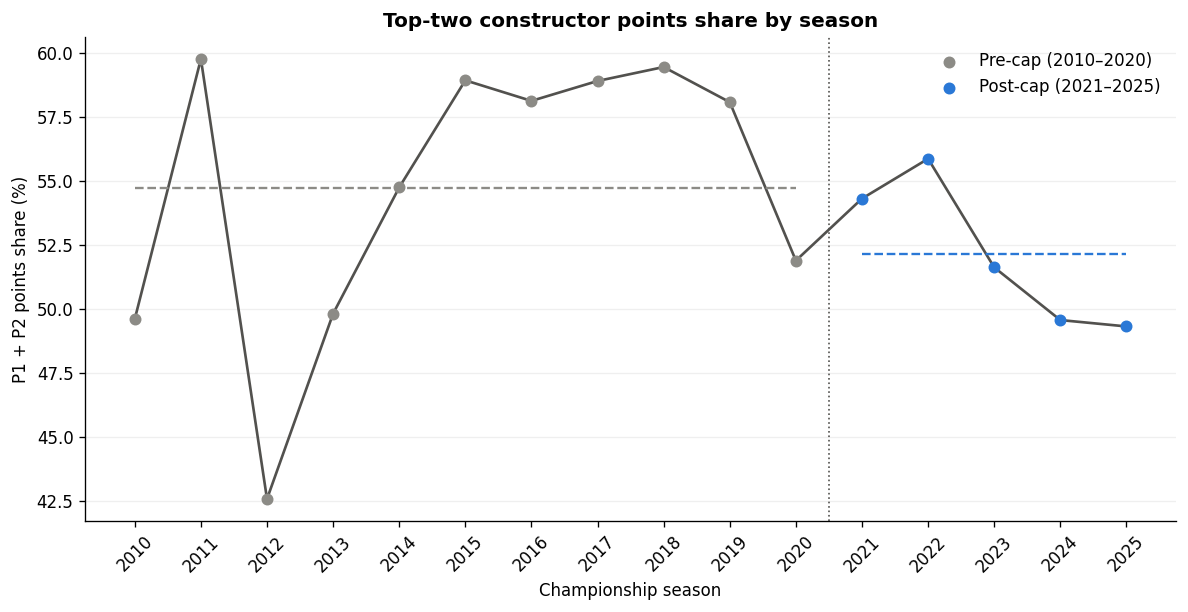

**Takeaway.** Average CR2 fell from 54.72% to 52.14%, a change of -2.58 percentage points. The post-cap years were not uniformly lower: 2022 reached 55.87%, above the pre-cap mean.

In [10]:
# Chart 1: compare the top two teams' points share before and after the cost cap
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(metrics["year"], metrics["cr2_pct"], color="#52514e", linewidth=1.6, zorder=2)
for era, frame in metrics.groupby("era", sort=False):
    ax.scatter(frame["year"], frame["cr2_pct"], color=ERA_COLORS[era], s=38, zorder=3, label=era)
    ax.hlines(frame["cr2_pct"].mean(), frame["year"].min(), frame["year"].max(),
              color=ERA_COLORS[era], linestyles="--", linewidth=1.4)
ax.axvline(2020.5, color="#52514e", linestyle=":", linewidth=1)
ax.set(title='Top-two constructor points share by season', xlabel="Championship season", ylabel='P1 + P2 points share (%)')
ax.set_xticks(range(2010, 2026))
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


display(Markdown(f"""**Takeaway.** Average CR2 fell from {pre_mean:.2f}% to {post_mean:.2f}%, a change of {mean_difference:+.2f} percentage points. The post-cap years were not uniformly lower: 2022 reached {metrics.loc[metrics.year.eq(2022), "cr2_pct"].item():.2f}%, above the pre-cap mean."""))

### Chart 2 of 15: Midfield Points Share

**Did the P4–P7 group gain share?**

The group follows final championship positions, not fixed team names. Its members can change each season; Chart 9 identifies them. Dashed lines show era averages.

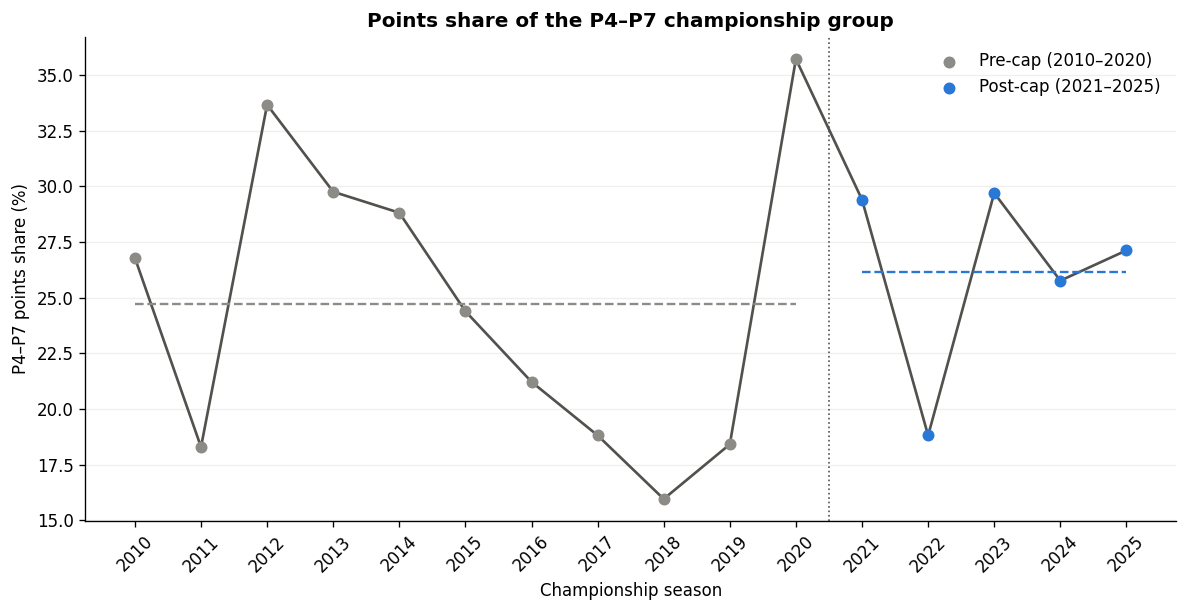

**Takeaway.** The P4–P7 average increased from 24.71% to 26.16% (+1.45 percentage points). Within the post-cap period, the share ranged from 18.81% to 29.70%.

In [11]:
# Chart 2: track the points share of teams finishing fourth through seventh.
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(metrics["year"], metrics["midfield_p4_p7_pct"], color="#52514e", linewidth=1.6, zorder=2)
for era, frame in metrics.groupby("era", sort=False):
    ax.scatter(frame["year"], frame["midfield_p4_p7_pct"], color=ERA_COLORS[era], s=38, zorder=3, label=era)
    ax.hlines(frame["midfield_p4_p7_pct"].mean(), frame["year"].min(), frame["year"].max(),
              color=ERA_COLORS[era], linestyles="--", linewidth=1.4)
ax.axvline(2020.5, color="#52514e", linestyle=":", linewidth=1)
ax.set(title='Points share of the P4–P7 championship group', xlabel="Championship season", ylabel='P4–P7 points share (%)')
ax.set_xticks(range(2010, 2026))
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


display(Markdown(f"""**Takeaway.** The P4–P7 average increased from {era_summary.loc[0, "midfield_mean_pct"]:.2f}% to {era_summary.loc[1, "midfield_mean_pct"]:.2f}% (+{era_summary.loc[1, "midfield_mean_pct"]-era_summary.loc[0, "midfield_mean_pct"]:.2f} percentage points). Within the post-cap period, the share ranged from {metrics.loc[metrics.year.ge(2021), "midfield_p4_p7_pct"].min():.2f}% to {metrics.loc[metrics.year.ge(2021), "midfield_p4_p7_pct"].max():.2f}%."""))

### Chart 3 of 15: Variation Between Seasons

**Did CR2 and midfield share become less variable?**

Each dot is a season. The box contains the middle half of values, with the median marked inside. The table reports sample standard deviations in percentage points. Less variation does not by itself mean a more balanced grid.

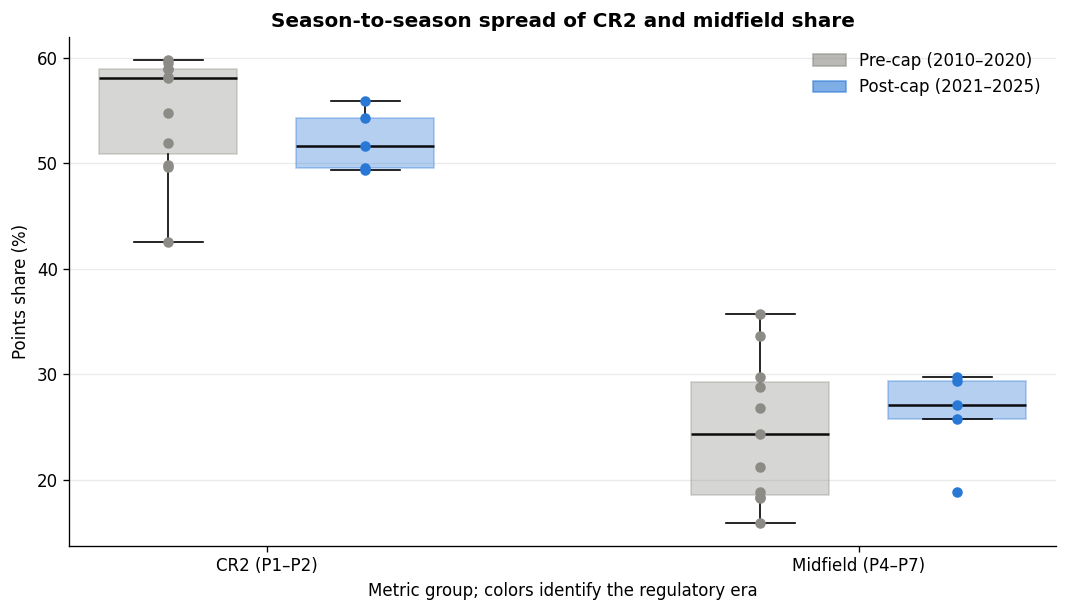

,CR2 SD (pp),Midfield SD (pp)
era,,
Pre-cap (2010–2020),5.59,6.73
Post-cap (2021–2025),2.89,4.42


**Takeaway.** CR2 standard deviation fell from 5.59 to 2.89 percentage points; midfield standard deviation fell from 6.73 to 4.42. Both shares varied less across the five post-cap seasons.

In [12]:
# Chart 3: CR2 and midfield distributions on a shared percentage axis.
fig, ax = plt.subplots(figsize=(9, 5.2))
groups = [("CR2 (P1–P2)", "cr2_pct"), ("Midfield (P4–P7)", "midfield_p4_p7_pct")]
positions, data, colors = [], [], []
for g_index, (label, column) in enumerate(groups):
    for e_index, era in enumerate([ERA_PRE, ERA_POST]):
        positions.append(g_index * 3 + e_index + 1)
        data.append(metrics.loc[metrics["era"].eq(era), column].to_numpy())
        colors.append(ERA_COLORS[era])
boxes = ax.boxplot(data, positions=positions, widths=0.7, showfliers=False, patch_artist=True,
                   medianprops={"color": "#0b0b0b", "linewidth": 1.5})
for patch, color in zip(boxes["boxes"], colors):
    patch.set(facecolor=color, alpha=0.35, edgecolor=color)
for x, values, color in zip(positions, data, colors):
    ax.scatter(np.full(len(values), x), values, color=color, s=28, zorder=3)
ax.set_xticks([1.5, 4.5], [g[0] for g in groups])
ax.set(title="Season-to-season spread of CR2 and midfield share", ylabel="Points share (%)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ERA_COLORS[e], alpha=0.6) for e in (ERA_PRE, ERA_POST)],
          labels=[ERA_PRE, ERA_POST], frameon=False, loc="upper right")
ax.set_xlabel("Metric group; colors identify the regulatory era")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

spread = metrics.groupby("era", sort=False)[["cr2_pct", "midfield_p4_p7_pct"]].std().round(2)
display(spread.rename(columns={"cr2_pct": "CR2 SD (pp)", "midfield_p4_p7_pct": "Midfield SD (pp)"}))

display(Markdown(f"""**Takeaway.** CR2 standard deviation fell from {era_summary.loc[0, "cr2_std_pct_points"]:.2f} to {era_summary.loc[1, "cr2_std_pct_points"]:.2f} percentage points; midfield standard deviation fell from {era_summary.loc[0, "midfield_std_pct_points"]:.2f} to {era_summary.loc[1, "midfield_std_pct_points"]:.2f}. Both shares varied less across the five post-cap seasons."""))

## 4. Sensitivity to the Baseline and Individual Seasons

**Does the comparison period change the answer?**

We keep the original comparison and add the more recent 2014–2020 baseline. We also leave out each post-cap season in turn. These checks show whether an era average depends heavily on the years selected.

### Chart 4 of 15: Two Pre-Cap Baselines

**Does the CR2 result change against 2014–2020?**

The first table compares CR2 under both baselines. A supporting table repeats the comparisons for midfield and Big Three shares. All six exploratory tests are reported, including those above 0.05.

,baseline,pre_n,pre_mean_pct,post_mean_pct,difference_pp,welch_t,p_value
0,2010–2020 (original),11,54.722,52.14,-2.581,-1.215,0.245
1,2014–2020 (sensitivity),7,57.166,52.14,-5.026,-3.009,0.016


,metric,baseline,difference_pp,welch_t,p_value
0,midfield_p4_p7_pct,2010–2020 (original),1.448,0.511,0.619
1,midfield_p4_p7_pct,2014–2020 (sensitivity),2.828,0.862,0.409
2,big_three_pct,2010–2020 (original),-1.692,-0.313,0.763
3,big_three_pct,2014–2020 (sensitivity),-6.325,-1.173,0.278


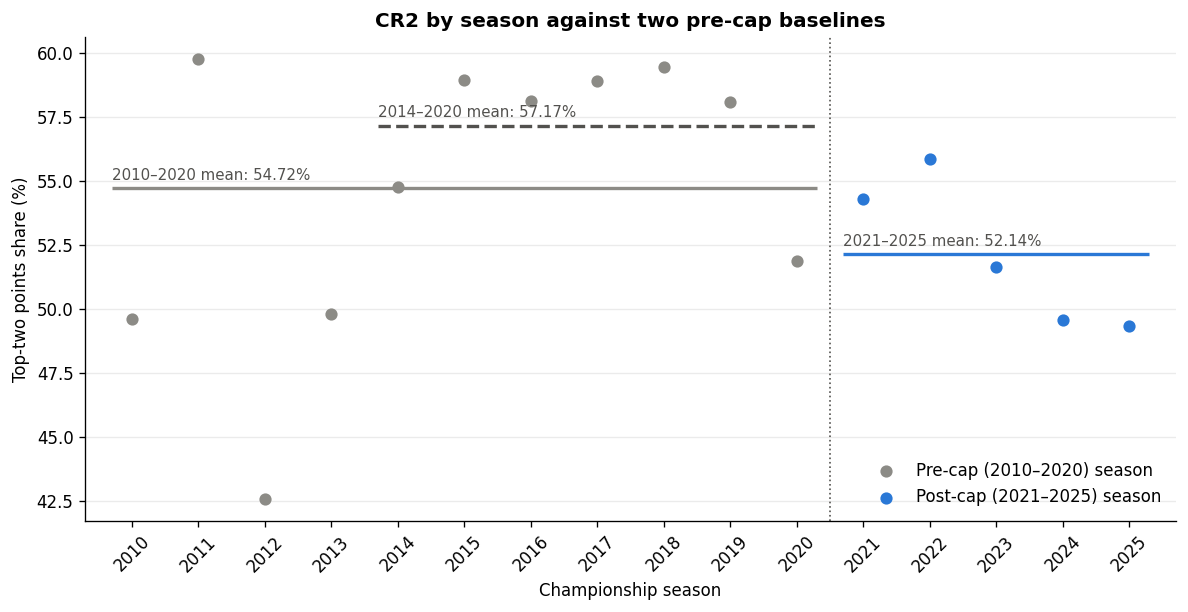

**Takeaway.** Against 2014–2020, CR2 fell by 5.03 percentage points (p = 0.016); the original decline was 2.58 points (p = 0.245). Only one of the six exploratory comparisons is below 0.05, showing how much the baseline matters.

In [13]:
# Chart 4: the original 2010–2020 baseline and a 2014–2020 sensitivity baseline, both tested as post − pre.
post_cr2 = metrics.loc[metrics["year"].between(2021, 2025), "cr2_pct"]
baselines = {"2010–2020 (original)": (2010, 2020), "2014–2020 (sensitivity)": (2014, 2020)}
rows = []
for label, (start, end) in baselines.items():
    pre = metrics.loc[metrics["year"].between(start, end), "cr2_pct"]
    test = ttest_ind(post_cr2, pre, equal_var=False)  # first sample minus second = post − pre
    rows.append({"baseline": label, "pre_n": len(pre), "pre_mean_pct": pre.mean(),
                 "post_mean_pct": post_cr2.mean(), "difference_pp": post_cr2.mean() - pre.mean(),
                 "welch_t": test.statistic, "p_value": test.pvalue})
baseline_tests = pd.DataFrame(rows)
display(baseline_tests.round(3))

# Supporting table: the same two baselines for the other two metrics (quoted in the text, not charted).
support_rows = []
for metric in ["midfield_p4_p7_pct", "big_three_pct"]:
    post = metrics.loc[metrics["year"].between(2021, 2025), metric]
    for label, (start, end) in baselines.items():
        pre = metrics.loc[metrics["year"].between(start, end), metric]
        test = ttest_ind(post, pre, equal_var=False)
        support_rows.append({"metric": metric, "baseline": label, "difference_pp": post.mean() - pre.mean(),
                             "welch_t": test.statistic, "p_value": test.pvalue})
display(pd.DataFrame(support_rows).round(3))

fig, ax = plt.subplots(figsize=(10, 5.2))
for era, frame in metrics.groupby("era", sort=False):
    ax.scatter(frame["year"], frame["cr2_pct"], color=ERA_COLORS[era], s=40, zorder=3, label=f"{era} season")
segments = [((2010, 2020), "#8c8b86", "-", "2010–2020 mean"), ((2014, 2020), "#52514e", "--", "2014–2020 mean"),
            ((2021, 2025), "#2a78d6", "-", "2021–2025 mean")]
for (start, end), color, style, label in segments:
    value = metrics.loc[metrics["year"].between(start, end), "cr2_pct"].mean()
    ax.hlines(value, start - 0.3, end + 0.3, colors=color, linestyles=style, linewidth=2)
    ax.annotate(f"{label}: {value:.2f}%", (start - 0.3, value), textcoords="offset points", xytext=(0, 5),
                fontsize=9, color="#52514e")
ax.axvline(2020.5, color="#52514e", linestyle=":", linewidth=1)
ax.set(title="CR2 by season against two pre-cap baselines", xlabel="Championship season",
       ylabel="Top-two points share (%)", xlim=(2009.3, 2025.7))
ax.set_xticks(range(2010, 2026))
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

display(Markdown(f"""**Takeaway.** Against 2014–2020, CR2 fell by {abs(baseline_tests.loc[1, "difference_pp"]):.2f} percentage points (p = {baseline_tests.loc[1, "p_value"]:.3f}); the original decline was {abs(baseline_tests.loc[0, "difference_pp"]):.2f} points (p = {baseline_tests.loc[0, "p_value"]:.3f}). Only one of the six exploratory comparisons is below 0.05, showing how much the baseline matters."""))

### Chart 5 of 15: The Influence of 2025

**Does the Big Three decline survive excluding 2025?**

We show annual shares and era averages, then leave out each post-cap year in turn. Ferrari, Mercedes, and Red Bull remain the fixed Big Three throughout.

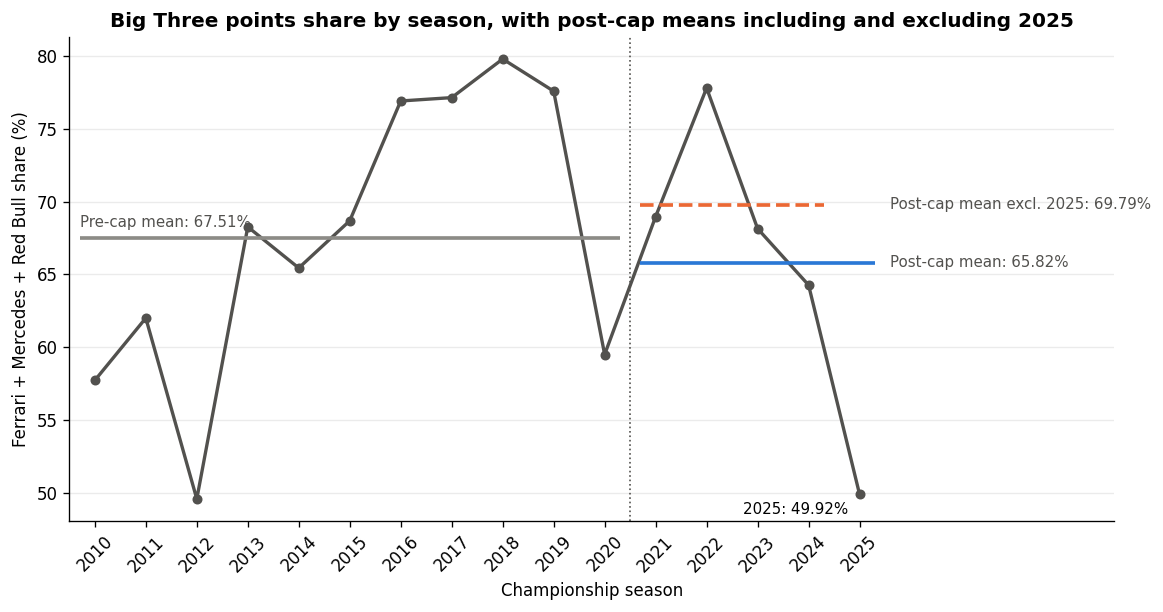

,season_left_out,post_cap_cr2_mean,post_cap_big_three_mean
0,2021,51.60,65.03
1,2022,51.21,62.83
2,2023,52.27,65.24
3,2024,52.78,66.21
4,2025,52.85,69.79


Big Three: pre 67.51% | post 65.82% | post excl. 2025 69.79%
Big Three share 2022–2025: [77.79, 68.14, 64.27, 49.92]


**Takeaway.** The Big Three average fell from 67.51% to 65.82%. Leave out 2025 and the post-cap average is higher, at 69.79%, reversing the comparison.

In [14]:
# Chart 5: Big Three share by season, with era means including and excluding 2025.
pre_b3 = metrics.loc[metrics["year"].le(2020), "big_three_pct"]
post_b3 = metrics.loc[metrics["year"].ge(2021), "big_three_pct"]
post_b3_ex2025 = metrics.loc[metrics["year"].between(2021, 2024), "big_three_pct"]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(metrics["year"], metrics["big_three_pct"], color="#52514e", linewidth=2, marker="o", markersize=5)
for (start, end, value, color, style, label) in [
        (2010, 2020, pre_b3.mean(), "#8c8b86", "-", "Pre-cap mean"),
        (2021, 2025, post_b3.mean(), "#2a78d6", "-", "Post-cap mean"),
        (2021, 2024, post_b3_ex2025.mean(), "#eb6834", "--", "Post-cap mean excl. 2025")]:
    ax.hlines(value, start - 0.3, end + 0.3, colors=color, linestyles=style, linewidth=2.2)
    label_x, offset = (start - 0.3, (0, 5)) if start == 2010 else (2025.6, (0, 0))
    ax.annotate(f"{label}: {value:.2f}%", (label_x, value), textcoords="offset points", xytext=offset,
                va="bottom" if start == 2010 else "center", fontsize=9, color="#52514e")
ax.annotate(f"2025: {metrics.loc[metrics['year'].eq(2025), 'big_three_pct'].item():.2f}%",
            (2025, metrics.loc[metrics["year"].eq(2025), "big_three_pct"].item()),
            textcoords="offset points", xytext=(-70, -12), fontsize=9)
ax.axvline(2020.5, color="#52514e", linestyle=":", linewidth=1)
ax.set(title="Big Three points share by season, with post-cap means including and excluding 2025",
       xlabel="Championship season", ylabel="Ferrari + Mercedes + Red Bull share (%)", xlim=(2009.5, 2030))
ax.set_xticks(range(2010, 2026))
ax.tick_params(axis="x", labelrotation=45)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# Leave-one-out: how much does each post-cap season move the post-cap mean?
loo = pd.DataFrame([{
    "season_left_out": year,
    "post_cap_cr2_mean": metrics.loc[metrics["year"].ge(2021) & metrics["year"].ne(year), "cr2_pct"].mean(),
    "post_cap_big_three_mean": metrics.loc[metrics["year"].ge(2021) & metrics["year"].ne(year), "big_three_pct"].mean(),
} for year in range(2021, 2026)])
display(loo.round(2))
print(f"Big Three: pre {pre_b3.mean():.2f}% | post {post_b3.mean():.2f}% | post excl. 2025 {post_b3_ex2025.mean():.2f}%")
print("Big Three share 2022–2025:", metrics.loc[metrics["year"].between(2022, 2025), "big_three_pct"].round(2).tolist())

display(Markdown(f"""**Takeaway.** The Big Three average fell from {pre_b3.mean():.2f}% to {post_b3.mean():.2f}%. Leave out 2025 and the post-cap average is higher, at {post_b3_ex2025.mean():.2f}%, reversing the comparison."""))

**Section takeaway.** Changing the baseline affects the CR2 result. Excluding 2025 reverses the Big Three comparison. Neither finding is captured by a single before-and-after average.

## 5. Which Teams Gained and Lost?

**Did gains reach several teams, or mainly change the leading names?**

We now follow individual lineages. Team means use only seasons in which they competed: five pre-cap seasons for Haas and eleven for the other continuing lineages.

### Chart 6 of 15: Gains and Losses by Team

**Which continuing teams gained or lost average points share?**

Each bar is the post-cap mean minus the pre-cap mean. The table shows the seasons behind each comparison; missing seasons are excluded from team means.

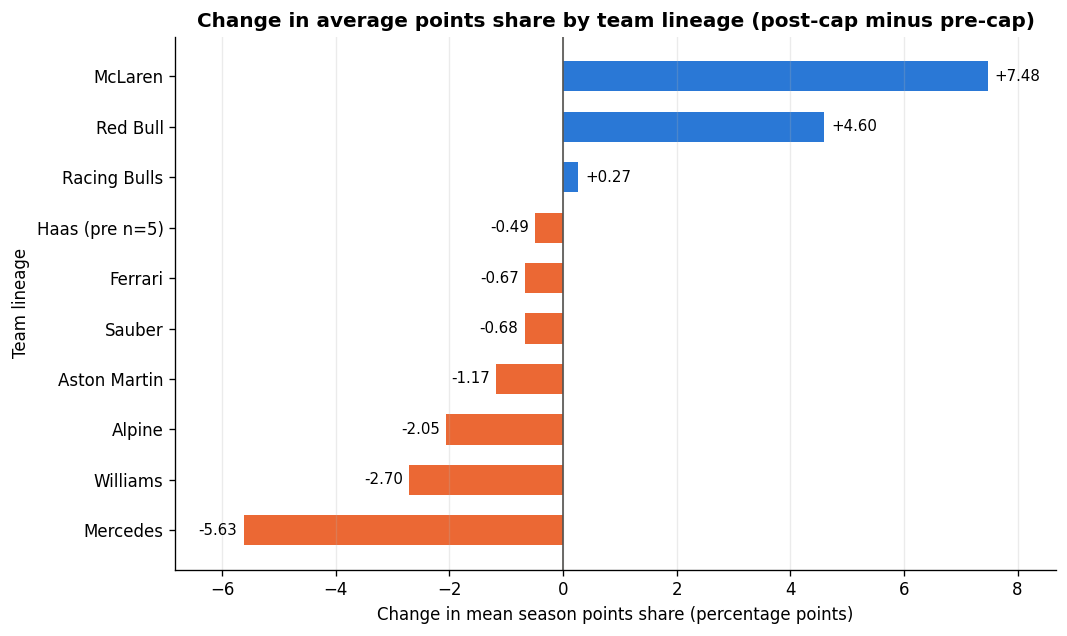

,pre_mean_pct,post_mean_pct,pre_seasons,post_seasons,change_pp
lineage,,,,,
Mercedes,25.97,20.34,11,5,-5.63
Williams,4.37,1.67,11,5,-2.70
Alpine,6.56,4.51,11,5,-2.05
Aston Martin,6.00,4.83,11,5,-1.17
Sauber,1.95,1.28,11,5,-0.68
Ferrari,19.54,18.87,11,5,-0.67
Haas,1.94,1.45,5,5,-0.49
Racing Bulls,2.56,2.83,11,5,0.27
Red Bull,22.01,26.61,11,5,4.60


**Takeaway.** McLaren gained 7.48 percentage points and Red Bull gained 4.60. Mercedes lost 5.63 and Williams lost 2.70; gains were concentrated in a few lineages.

In [15]:
# Chart 6: post-cap mean minus pre-cap mean share for lineages that raced in both eras.
era_means = lineage_season.pivot_table(index="lineage", columns="era", values="points_share", aggfunc="mean")
era_counts = lineage_season.pivot_table(index="lineage", columns="era", values="year", aggfunc="count")
continuing = era_means.dropna().index
team_change = pd.DataFrame({
    "pre_mean_pct": era_means.loc[continuing, ERA_PRE],
    "post_mean_pct": era_means.loc[continuing, ERA_POST],
    "pre_seasons": era_counts.loc[continuing, ERA_PRE].astype(int),
    "post_seasons": era_counts.loc[continuing, ERA_POST].astype(int),
})
team_change["change_pp"] = team_change["post_mean_pct"] - team_change["pre_mean_pct"]
team_change = team_change.sort_values("change_pp")

fig, ax = plt.subplots(figsize=(9, 5.4))
bar_colors = np.where(team_change["change_pp"] >= 0, "#2a78d6", "#eb6834")
labels = [f"{name} (pre n={n})" if n < 11 else name for name, n in zip(team_change.index, team_change["pre_seasons"])]
ax.barh(labels, team_change["change_pp"], color=bar_colors, height=0.6)
for y, value in enumerate(team_change["change_pp"]):
    ax.annotate(f"{value:+.2f}", (value, y), xytext=(4 if value >= 0 else -4, 0), textcoords="offset points",
                ha="left" if value >= 0 else "right", va="center", fontsize=9)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlim(team_change["change_pp"].min() - 1.2, team_change["change_pp"].max() + 1.2)
ax.set(title="Change in average points share by team lineage (post-cap minus pre-cap)",
       xlabel="Change in mean season points share (percentage points)")
ax.set_ylabel("Team lineage")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
display(team_change.round(2))

display(Markdown(f"""**Takeaway.** McLaren gained {team_change.loc["McLaren", "change_pp"]:.2f} percentage points and Red Bull gained {team_change.loc["Red Bull", "change_pp"]:.2f}. Mercedes lost {abs(team_change.loc["Mercedes", "change_pp"]):.2f} and Williams lost {abs(team_change.loc["Williams", "change_pp"]):.2f}; gains were concentrated in a few lineages."""))

### Chart 7 of 15: Timing of the Leading Teams' Results

**When did the leading teams gain or lose share?**

Annual paths show what sits behind Chart 6's averages, including McLaren's recovery before 2021.

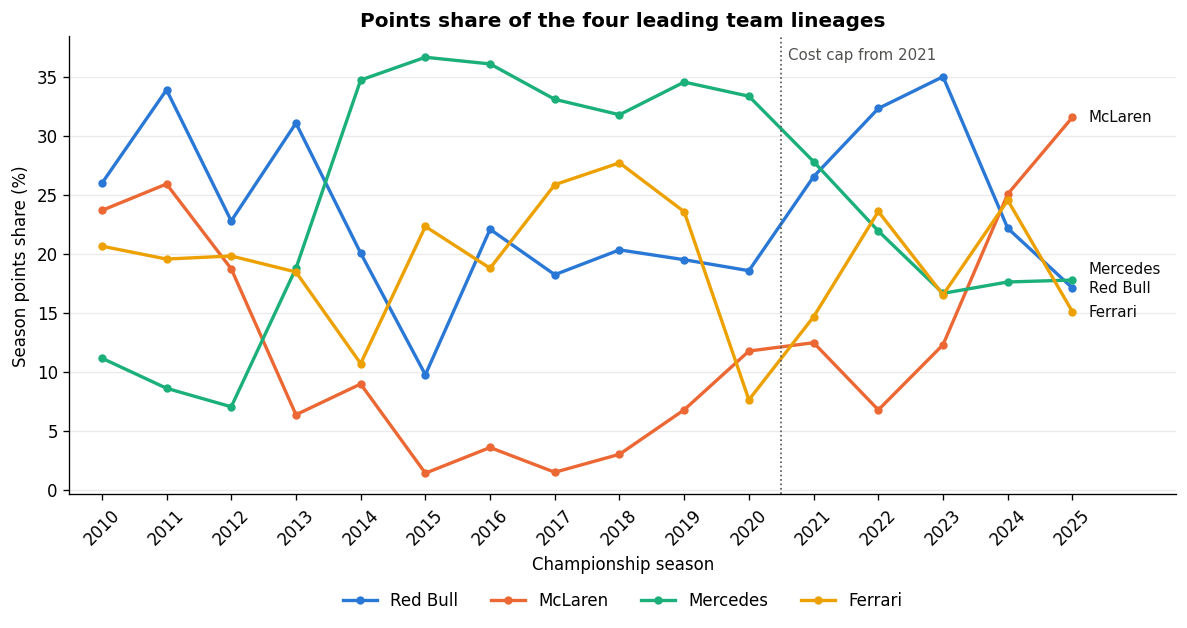

lineage,Red Bull,McLaren,Mercedes,Ferrari
year,,,,
2017,18.2,1.5,33.1,25.8
2020,18.6,11.8,33.3,7.6
2021,26.5,12.5,27.8,14.7
2022,32.3,6.8,21.9,23.6
2023,35.0,12.3,16.6,16.5
2024,22.2,25.0,17.6,24.5
2025,17.1,31.6,17.8,15.1


**Takeaway.** McLaren rose from 1.49% in 2017 to 25.05% in 2024 and 31.55% in 2025. Its recovery was already visible in 2020, when it held 11.75%.

In [16]:
# Chart 7: season-by-season share for the four leading lineages followed in this analysis.
focus = lineage_season.loc[lineage_season["lineage"].isin(FOCUS_TEAMS)]
trajectory = focus.pivot(index="year", columns="lineage", values="points_share")[FOCUS_TEAMS]

fig, ax = plt.subplots(figsize=(10, 5.4))
for team in FOCUS_TEAMS:
    ax.plot(trajectory.index, trajectory[team], color=TEAM_COLORS[team], linewidth=2, marker="o", markersize=4)
# Direct end labels, nudged apart so close 2025 values stay readable.
label_y = trajectory.loc[2025].sort_values()
placed = []
for team, value in label_y.items():
    y = max(value, placed[-1] + 1.6) if placed else value
    placed.append(y)
    ax.annotate(team, (2025.25, y), va="center", fontsize=9, color="#0b0b0b")
ax.axvline(2020.5, color="#52514e", linestyle=":", linewidth=1)
ax.annotate("Cost cap from 2021", (2020.6, ax.get_ylim()[1] * 0.95), fontsize=9, color="#52514e")
ax.set(title="Points share of the four leading team lineages", xlabel="Championship season",
       ylabel="Season points share (%)", xlim=(2009.5, 2026.6))
ax.set_xticks(range(2010, 2026))
ax.tick_params(axis="x", labelrotation=45)
ax.legend(FOCUS_TEAMS, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
display(trajectory.loc[[2017, 2020, 2021, 2022, 2023, 2024, 2025]].round(1))

display(Markdown(f"""**Takeaway.** McLaren rose from {trajectory.loc[2017, "McLaren"]:.2f}% in 2017 to {trajectory.loc[2024, "McLaren"]:.2f}% in 2024 and {trajectory.loc[2025, "McLaren"]:.2f}% in 2025. Its recovery was already visible in 2020, when it held {trajectory.loc[2020, "McLaren"]:.2f}%."""))

### Chart 8 of 15: Championship Positions Across Names

**How did each lineage's rank change over time?**

Lower ranks are better. Hatched cells mean the team did not enter that season. The color scale is consistent across the grid.

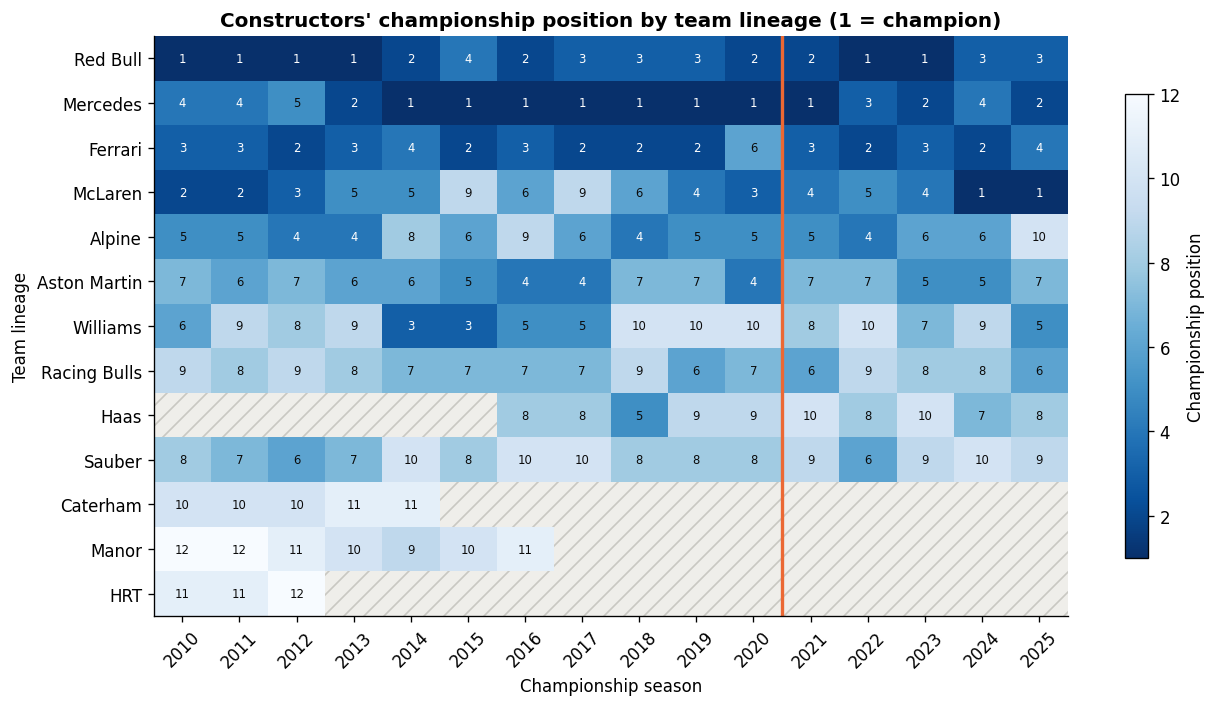

**Takeaway.** McLaren went from P9 in 2015 and 2017 to P1 in 2024 and 2025. Williams finished P10 in 2018–2020 and recovered to P5 in 2025.

In [17]:
# Chart 8: championship position by lineage and season; blank (hatched) cells = team not on the grid.
order = ranks.mean(axis=1).sort_values().index
grid = ranks.loc[order].astype(float)

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_facecolor("#efeeea")
image = ax.imshow(grid, cmap="Blues_r", aspect="auto", vmin=1, vmax=12, zorder=1)
for (i, j), value in np.ndenumerate(grid.to_numpy()):
    if not np.isnan(value):
        ax.text(j, i, f"{int(value)}", ha="center", va="center", fontsize=7,
                color="white" if value <= 4 else "#0b0b0b")
ax.set_xticks(range(len(grid.columns)), grid.columns, rotation=45)
ax.set_yticks(range(len(grid.index)), grid.index)
ax.axvline(list(grid.columns).index(2021) - 0.5, color="#eb6834", linewidth=2)
ax.set(title="Constructors' championship position by team lineage (1 = champion)", xlabel="Championship season")
ax.set_ylabel("Team lineage")
fig.colorbar(image, ax=ax, label="Championship position", shrink=0.8)
ax.add_patch(plt.Rectangle((-0.5, -0.5), len(grid.columns), len(grid.index), fill=False, hatch="//",
                           edgecolor="#c9c8c2", linewidth=0, zorder=0.5))
fig.tight_layout()
plt.show()

display(Markdown(f"""**Takeaway.** McLaren went from P9 in 2015 and 2017 to P1 in 2024 and 2025. Williams finished P10 in 2018–2020 and recovered to P{int(ranks.loc["Williams", 2025])} in 2025."""))

### Chart 9 of 15: Who Filled the Midfield?

**Which teams finished P4–P7, and did membership change?**

The denominator is all 11 pre-cap or all 5 post-cap seasons. A shorter participation history therefore lowers a team's frequency. Haas, for example, entered only five pre-cap seasons.

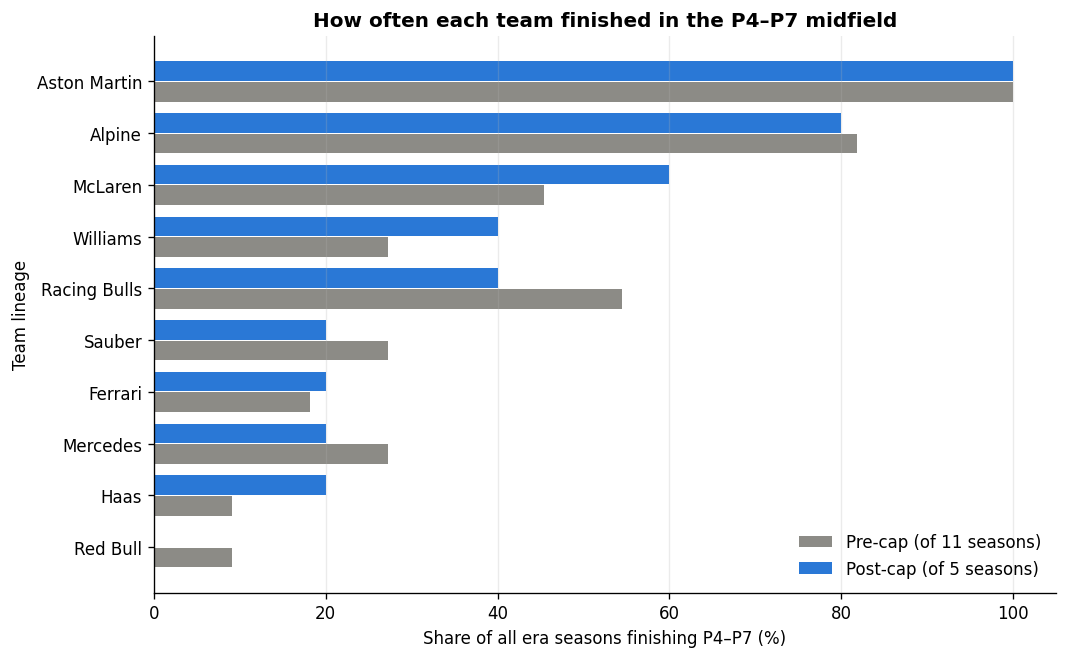

era,pre_seasons_P4_P7,post_seasons_P4_P7
lineage,,
Alpine,9,4
Aston Martin,11,5
Caterham,0,0
Ferrari,2,1
HRT,0,0
Haas,1,1
Manor,0,0
McLaren,5,3
Mercedes,3,1


**Takeaway.** The Aston Martin lineage finished P4–P7 in all 11 pre-cap and 5 post-cap seasons. McLaren appeared in this group in 5 of 11 and 3 of 5 seasons, so the same position range did not always contain the same teams.

In [18]:
# Chart 9: share of each era's seasons in which a lineage finished P4–P7.
in_midfield = lineage_season.assign(midfield=lineage_season["position"].between(4, 7))
seasons_per_era = {ERA_PRE: 11, ERA_POST: 5}
membership = (in_midfield.groupby(["lineage", "era"])["midfield"].sum().unstack(fill_value=0)
              .reindex(columns=[ERA_PRE, ERA_POST], fill_value=0))
membership_pct = membership.div(pd.Series(seasons_per_era)) * 100
membership_pct = membership_pct.loc[membership.sum(axis=1).gt(0)].sort_values(ERA_POST)

fig, ax = plt.subplots(figsize=(9, 5.6))
y = np.arange(len(membership_pct))
ax.barh(y - 0.2, membership_pct[ERA_PRE], height=0.38, color=ERA_COLORS[ERA_PRE], label="Pre-cap (of 11 seasons)")
ax.barh(y + 0.2, membership_pct[ERA_POST], height=0.38, color=ERA_COLORS[ERA_POST], label="Post-cap (of 5 seasons)")
ax.set_yticks(y, membership_pct.index)
ax.set(title="How often each team finished in the P4–P7 midfield", xlabel="Share of all era seasons finishing P4–P7 (%)", xlim=(0, 105))
ax.legend(frameon=False, loc="lower right")
ax.set_ylabel("Team lineage")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
display(membership.rename(columns={ERA_PRE: "pre_seasons_P4_P7", ERA_POST: "post_seasons_P4_P7"}))

display(Markdown(f"""**Takeaway.** The Aston Martin lineage finished P4–P7 in all {int(membership.loc["Aston Martin", ERA_PRE])} pre-cap and {int(membership.loc["Aston Martin", ERA_POST])} post-cap seasons. McLaren appeared in this group in {int(membership.loc["McLaren", ERA_PRE])} of 11 and {int(membership.loc["McLaren", ERA_POST])} of 5 seasons, so the same position range did not always contain the same teams."""))

**Section takeaway.** McLaren and Red Bull show the largest gains among continuing teams. Several other lineages lose average share, so the midfield did not benefit uniformly.

## 6. Championship Mobility and the Fight at the Top

**Did the order change more, and did the leading two teams finish closer?**

Rank movement measures mobility; the P1–P2 margin measures closeness at the top. For movement, we compare lineages present in consecutive years and assign each transition to its ending year. There are ten pre-cap transitions (2011–2020) and five post-cap transitions (2021–2025), including 2020–2021.

### Chart 10 of 15: Year-to-Year Rank Changes

**How much did championship positions change between seasons?**

We average the absolute rank change for lineages present in both years. Entrants and exits are excluded from that year's pair.

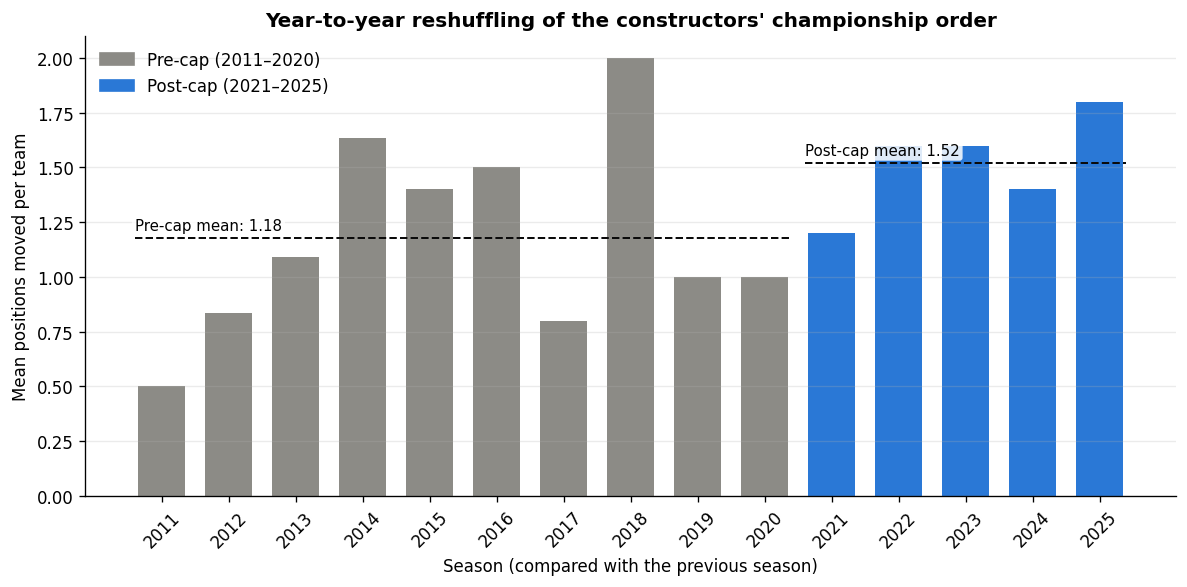

,mean,count
era,,
Pre-cap (2010–2020),1.18,10
Post-cap (2021–2025),1.52,5


Welch test, post − pre: t = 1.962, p = 0.072
Teams compared per season: 10–12


**Takeaway.** Mean movement increased from 1.18 to 1.52 places per team. The order changed more in this sample, although the exploratory comparison has p = 0.072.

In [19]:
# Chart 10: mean absolute change in championship position for lineages that raced in consecutive seasons.
churn_rows = []
for year in range(START_YEAR + 1, END_YEAR + 1):
    pair = ranks[[year - 1, year]].dropna()
    churn_rows.append({"year": year, "teams_compared": len(pair),
                       "mean_abs_position_change": (pair[year] - pair[year - 1]).abs().mean()})
churn = pd.DataFrame(churn_rows)
churn["era"] = np.where(churn["year"].lt(2021), ERA_PRE, ERA_POST)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(churn["year"], churn["mean_abs_position_change"], color=churn["era"].map(ERA_COLORS), width=0.7)
for era, frame in churn.groupby("era", sort=False):
    value = frame["mean_abs_position_change"].mean()
    ax.hlines(value, frame["year"].min() - 0.4, frame["year"].max() + 0.4, colors="#0b0b0b", linestyles="--", linewidth=1.2)
    ax.annotate(f"{era.split(' ')[0]} mean: {value:.2f}", (frame["year"].min() - 0.4, value),
                textcoords="offset points", xytext=(0, 5), fontsize=9,
                bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none", "alpha": 0.85})
ax.set(title="Year-to-year reshuffling of the constructors' championship order",
       xlabel="Season (compared with the previous season)", ylabel="Mean positions moved per team")
ax.set_xticks(churn["year"])
ax.tick_params(axis="x", labelrotation=45)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ERA_COLORS[e]) for e in (ERA_PRE, ERA_POST)],
          labels=["Pre-cap (2011–2020)", ERA_POST], frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
display(churn.groupby("era", sort=False)["mean_abs_position_change"].agg(["mean", "count"]).round(2))
churn_test = ttest_ind(churn.loc[churn["era"].eq(ERA_POST), "mean_abs_position_change"],
                       churn.loc[churn["era"].eq(ERA_PRE), "mean_abs_position_change"], equal_var=False)
print(f"Welch test, post − pre: t = {churn_test.statistic:.3f}, p = {churn_test.pvalue:.3f}")
print(f"Teams compared per season: {churn['teams_compared'].min()}–{churn['teams_compared'].max()}")

display(Markdown(f"""**Takeaway.** Mean movement increased from {churn.loc[churn.year.lt(2021), "mean_abs_position_change"].mean():.2f} to {churn.loc[churn.year.ge(2021), "mean_abs_position_change"].mean():.2f} places per team. The order changed more in this sample, although the exploratory comparison has p = {churn_test.pvalue:.3f}."""))

### Chart 11 of 15: The Championship Winning Margin

**Did the champion finish closer to the runner-up?**

We subtract P2's season points share from P1's. This is the constructors' championship margin, not the drivers' title margin or the time gap between cars on track.

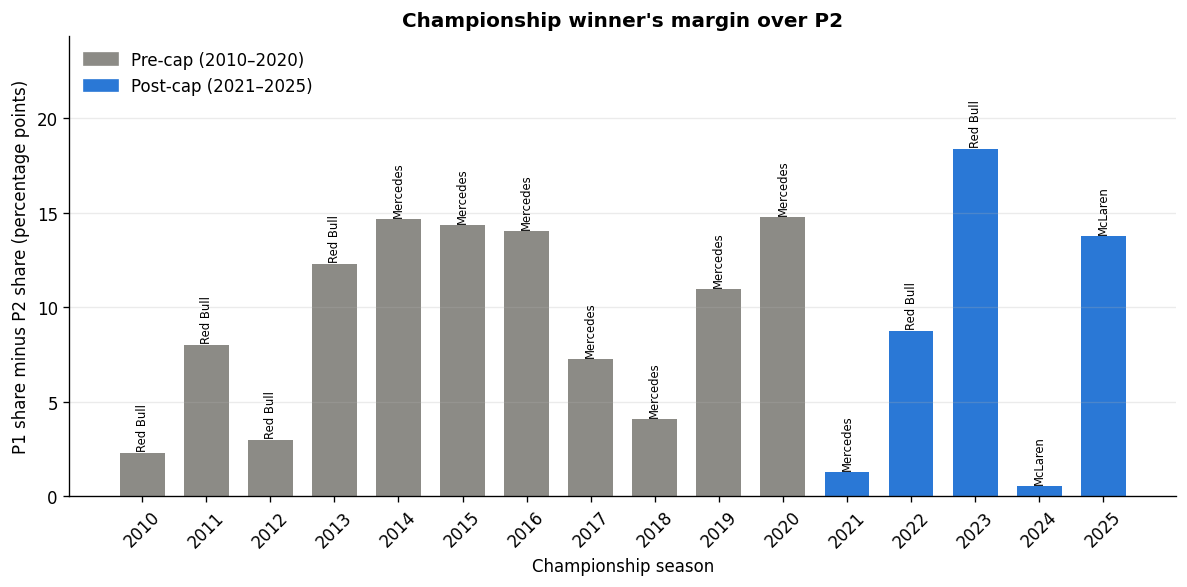

,mean,median,min,max
era,,,,
Pre-cap (2010–2020),9.60,10.98,2.29,14.78
Post-cap (2021–2025),8.53,8.72,0.53,18.35


**Takeaway.** The average P1–P2 margin narrowed from 9.60 to 8.53 percentage points. The post-cap period includes both the 0.53-point margin in 2024 and the 18.35-point gap in 2023.

In [20]:
# Chart 11: champion's points share minus runner-up's points share, by season.
top_two = standings.loc[standings["positionNumber"].isin([1, 2])].pivot(index="year", columns="positionNumber",
                                                                       values=["points_share", "lineage"])
title_gap = pd.DataFrame({
    "champion": top_two[("lineage", 1)], "runner_up": top_two[("lineage", 2)],
    "gap_pp": top_two[("points_share", 1)].astype(float) - top_two[("points_share", 2)].astype(float),
}).reset_index()
title_gap["era"] = np.where(title_gap["year"].lt(2021), ERA_PRE, ERA_POST)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(title_gap["year"], title_gap["gap_pp"], color=title_gap["era"].map(ERA_COLORS), width=0.7)
for _, row in title_gap.iterrows():
    ax.annotate(row["champion"], (row["year"], row["gap_pp"]), textcoords="offset points", xytext=(0, 3),
                ha="center", fontsize=7, rotation=90)
ax.set(title="Championship winner's margin over P2", xlabel="Championship season",
       ylabel="P1 share minus P2 share (percentage points)", ylim=(0, title_gap["gap_pp"].max() + 6))
ax.set_xticks(title_gap["year"])
ax.tick_params(axis="x", labelrotation=45)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ERA_COLORS[e]) for e in (ERA_PRE, ERA_POST)],
          labels=[ERA_PRE, ERA_POST], frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
display(title_gap.groupby("era", sort=False)["gap_pp"].agg(["mean", "median", "min", "max"]).round(2))

display(Markdown(f"""**Takeaway.** The average P1–P2 margin narrowed from {title_gap.loc[title_gap.year.lt(2021), "gap_pp"].mean():.2f} to {title_gap.loc[title_gap.year.ge(2021), "gap_pp"].mean():.2f} percentage points. The post-cap period includes both the {title_gap.loc[title_gap.year.eq(2024), "gap_pp"].item():.2f}-point margin in 2024 and the {title_gap.loc[title_gap.year.eq(2023), "gap_pp"].item():.2f}-point gap in 2023."""))

**Section takeaway.** More movement in rank can coexist with a dominant champion. The post-cap sample contains both a close title fight and a runaway season.

## 7. Grand Prix Wins and Podiums

**Did more teams reach the most visible race results?**

Season points summarize the championship. Wins and podiums show access to individual race results. We use Grand Prix finishes only, exclude sprints, and give each season equal weight in the era averages.

### Chart 12 of 15: Teams Reaching Wins and Podiums

**How many different teams won a race or reached a podium?**

Both bars count distinct lineages. Reaching a podium is a broader threshold of success than winning.

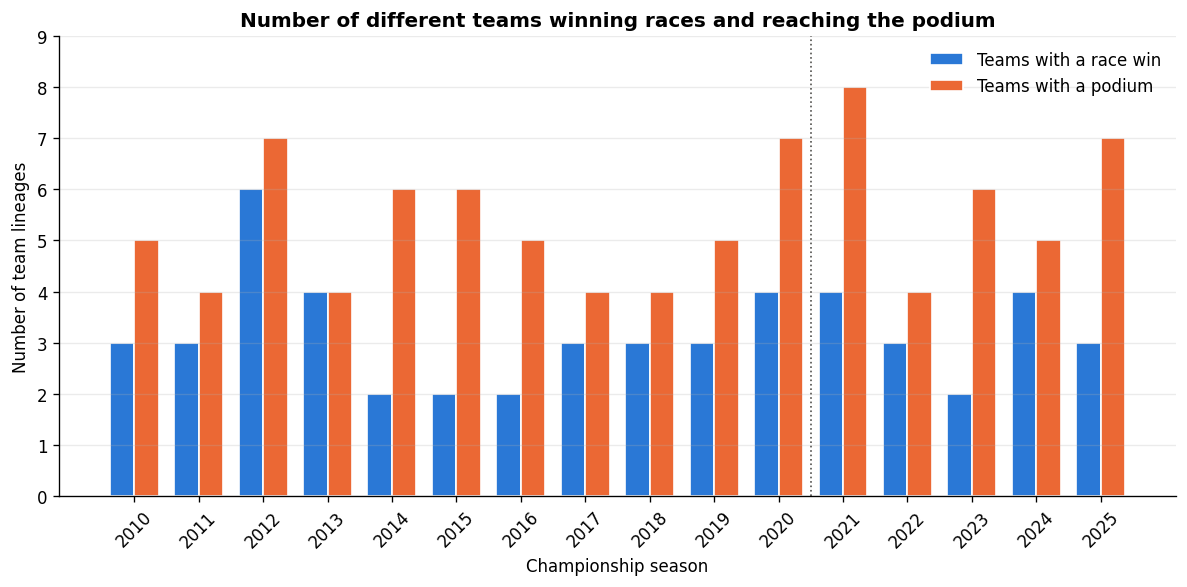

,distinct_winners,distinct_podium_teams
era,,
Pre-cap (2010–2020),3.18,5.18
Post-cap (2021–2025),3.20,6.00


Most podium teams in one season: 8 in 2021


**Takeaway.** Race-winning lineages averaged 3.18 before the cap and 3.20 afterward, almost unchanged. Podium-reaching lineages increased from 5.18 to 6.00.

In [21]:
# Chart 12: breadth of success — distinct race-winning and podium-reaching team lineages (one shared count axis).
fig, ax = plt.subplots(figsize=(10, 5))
width = 0.38
ax.bar(race_breadth["year"] - width / 2, race_breadth["distinct_winners"], width, color="#2a78d6", label="Teams with a race win", edgecolor="white", linewidth=1)
ax.bar(race_breadth["year"] + width / 2, race_breadth["distinct_podium_teams"], width, color="#eb6834", label="Teams with a podium", edgecolor="white", linewidth=1)
ax.axvline(2020.5, color="#52514e", linestyle=":", linewidth=1)
ax.set(title="Number of different teams winning races and reaching the podium",
       xlabel="Championship season", ylabel="Number of team lineages")
ax.set_xticks(race_breadth["year"])
ax.set_yticks(range(0, int(race_breadth["distinct_podium_teams"].max()) + 2))
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
display(race_breadth.groupby("era", sort=False)[["distinct_winners", "distinct_podium_teams"]].mean().round(2))
peak = race_breadth.loc[race_breadth["distinct_podium_teams"].idxmax()]
print(f"Most podium teams in one season: {peak['distinct_podium_teams']} in {peak['year']}")

display(Markdown(f"""**Takeaway.** Race-winning lineages averaged {race_breadth.loc[race_breadth.year.lt(2021), "distinct_winners"].mean():.2f} before the cap and {race_breadth.loc[race_breadth.year.ge(2021), "distinct_winners"].mean():.2f} afterward, almost unchanged. Podium-reaching lineages increased from {race_breadth.loc[race_breadth.year.lt(2021), "distinct_podium_teams"].mean():.2f} to {race_breadth.loc[race_breadth.year.ge(2021), "distinct_podium_teams"].mean():.2f}."""))

### Chart 13 of 15: Distribution of Race Wins

**Were wins shared among contenders or concentrated in one team?**

The same number of winning teams can conceal very different win shares. The chart highlights four lineages and combines the rest as Other. The leading-team table is calculated before that grouping.

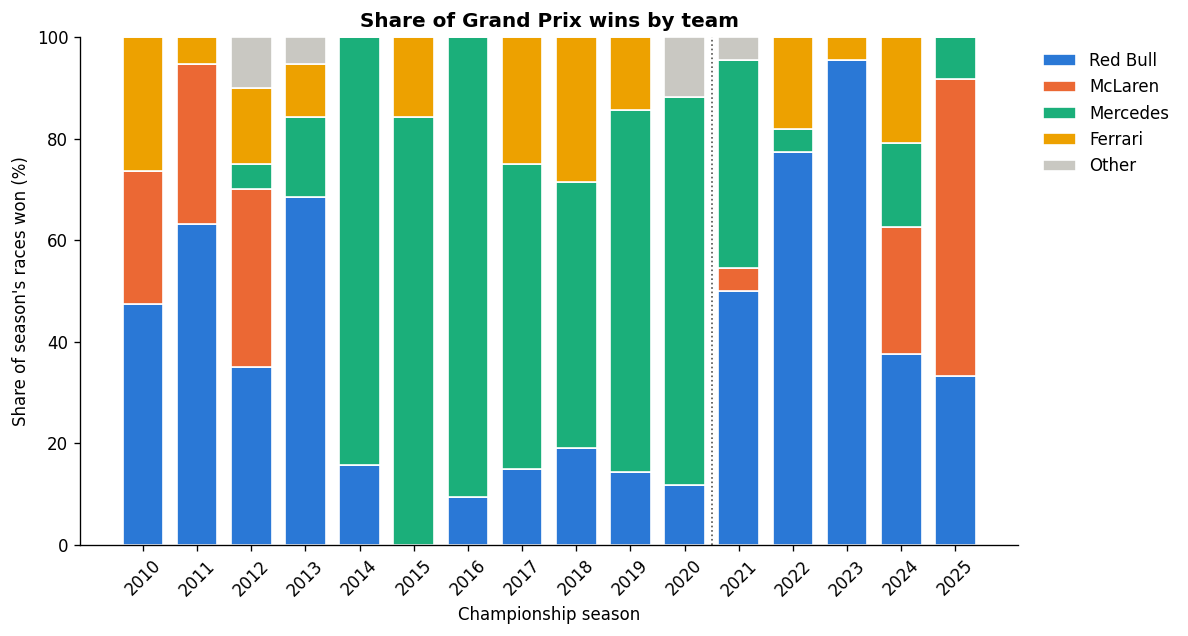

,top_team_win_share_pct,top_team
year,,
2019,71.4,Mercedes
2020,76.5,Mercedes
2021,50.0,Red Bull
2022,77.3,Red Bull
2023,95.5,Red Bull
2024,37.5,Red Bull
2025,58.3,McLaren


**Takeaway.** Red Bull won 95.45% of races in 2023. The leading team took 37.50% in 2024, followed by McLaren winning 58.33% in 2025; the distribution changed sharply between seasons.

In [22]:
# Chart 13: share of each season's Grand Prix wins by team (four leading lineages + all others).
wins = podium.loc[podium["positionNumber"].eq(1)].copy()
wins["team"] = np.where(wins["lineage"].isin(FOCUS_TEAMS), wins["lineage"], "Other")
win_share = (wins.groupby(["year", "team"]).size().unstack(fill_value=0)
             .reindex(columns=FOCUS_TEAMS + ["Other"], fill_value=0))
win_share = win_share.div(win_share.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5.4))
bottom = np.zeros(len(win_share))
for team in win_share.columns:
    ax.bar(win_share.index, win_share[team], bottom=bottom, color=TEAM_COLORS[team], width=0.75,
           label=team, edgecolor="white", linewidth=1)
    bottom += win_share[team].to_numpy()
ax.axvline(2020.5, color="#52514e", linestyle=":", linewidth=1)
ax.set(title="Share of Grand Prix wins by team", xlabel="Championship season", ylabel="Share of season's races won (%)")
ax.set_xticks(win_share.index)
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()
individual_wins = wins.groupby(["year", "lineage"]).size().unstack(fill_value=0)
individual_win_share = individual_wins.div(individual_wins.sum(axis=1), axis=0) * 100
assert np.allclose(win_share.sum(axis=1), 100, rtol=0, atol=1e-9)
top_team_win_share = individual_win_share.max(axis=1).rename("top_team_win_share_pct")
display(pd.concat([top_team_win_share, individual_win_share.idxmax(axis=1).rename("top_team")], axis=1).loc[2019:].round(1))

display(Markdown(f"""**Takeaway.** Red Bull won {individual_win_share.loc[2023, "Red Bull"]:.2f}% of races in 2023. The leading team took {individual_win_share.loc[2024].max():.2f}% in 2024, followed by McLaren winning {individual_win_share.loc[2025, "McLaren"]:.2f}% in 2025; the distribution changed sharply between seasons."""))

### Chart 14 of 15: Podiums Outside the Big Three

**What share of podium places went to other teams?**

The denominator is three driver podium places per Grand Prix. McLaren is outside the fixed Big Three, so its results contribute to this measure.

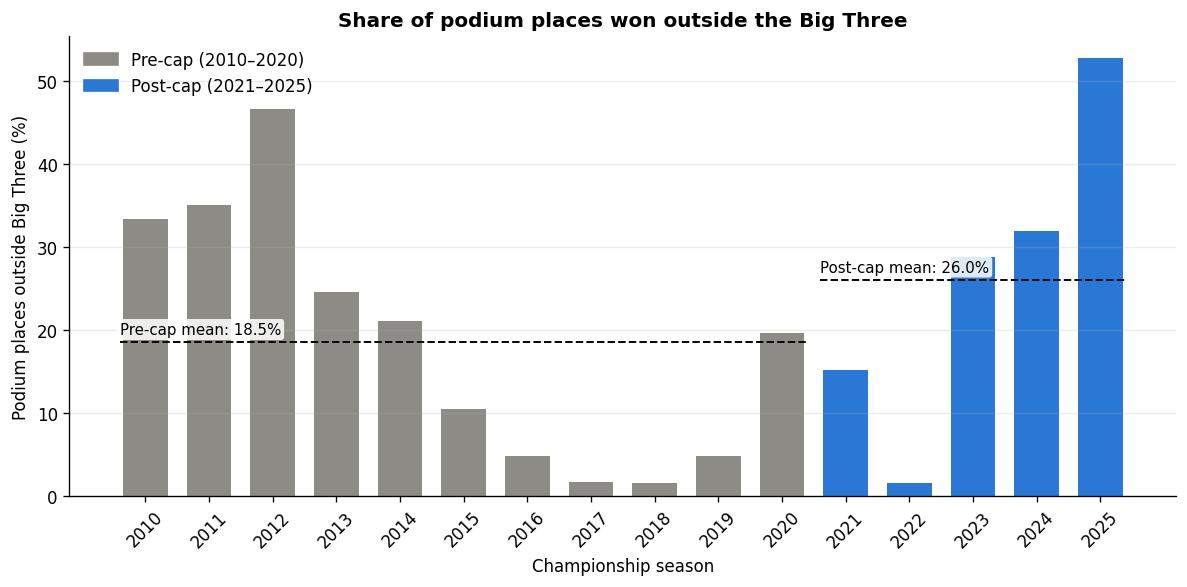

,year,races,non_big_three_podium_pct
11,2021,22,15.2
12,2022,22,1.5
13,2023,22,28.8
14,2024,24,31.9
15,2025,24,52.8


Outside Big Three: pre 18.5% | post 26.0% | post excl. 2025 19.3%


,window,mean_non_big_three_podium_pct
0,2010–2020,18.51
1,2021–2025,26.04
2,2021–2024,19.35


**Takeaway.** The average share of podium places outside the Big Three rose from 18.51% to 26.04%. Without 2025 it was 19.35%, close to the pre-cap level; 2025 alone reached 52.78%.

In [23]:
# Chart 14: podium places (3 per Grand Prix) won by lineages other than Ferrari, Mercedes and Red Bull.
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(race_breadth["year"], race_breadth["non_big_three_podium_pct"], color=race_breadth["era"].map(ERA_COLORS), width=0.7)
for era, frame in race_breadth.groupby("era", sort=False):
    value = frame["non_big_three_podium_pct"].mean()
    ax.hlines(value, frame["year"].min() - 0.4, frame["year"].max() + 0.4, colors="#0b0b0b", linestyles="--", linewidth=1.2)
    ax.annotate(f"{era.split(' ')[0]} mean: {value:.1f}%", (frame["year"].min() - 0.4, value),
                textcoords="offset points", xytext=(0, 5), fontsize=9,
                bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none", "alpha": 0.85})
ax.set(title="Share of podium places won outside the Big Three",
       xlabel="Championship season", ylabel="Podium places outside Big Three (%)")
ax.set_xticks(race_breadth["year"])
ax.tick_params(axis="x", labelrotation=45)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ERA_COLORS[e]) for e in (ERA_PRE, ERA_POST)],
          labels=[ERA_PRE, ERA_POST], frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
display(race_breadth.loc[race_breadth["year"].ge(2021), ["year", "races", "non_big_three_podium_pct"]].round(1))
pre_pod = race_breadth.loc[race_breadth["year"].le(2020), "non_big_three_podium_pct"].mean()
post_pod = race_breadth.loc[race_breadth["year"].ge(2021), "non_big_three_podium_pct"].mean()
post_pod_ex = race_breadth.loc[race_breadth["year"].between(2021, 2024), "non_big_three_podium_pct"].mean()
print(f"Outside Big Three: pre {pre_pod:.1f}% | post {post_pod:.1f}% | post excl. 2025 {post_pod_ex:.1f}%")
podium_pre = race_breadth.loc[race_breadth.year.lt(2021), "non_big_three_podium_pct"].mean()
podium_post = race_breadth.loc[race_breadth.year.ge(2021), "non_big_three_podium_pct"].mean()
podium_post_no_2025 = race_breadth.loc[race_breadth.year.between(2021, 2024), "non_big_three_podium_pct"].mean()
display(pd.DataFrame({"window": ["2010–2020", "2021–2025", "2021–2024"],
                      "mean_non_big_three_podium_pct": [podium_pre, podium_post, podium_post_no_2025]}).round(2))


display(Markdown(f"""**Takeaway.** The average share of podium places outside the Big Three rose from {podium_pre:.2f}% to {podium_post:.2f}%. Without 2025 it was {podium_post_no_2025:.2f}%, close to the pre-cap level; 2025 alone reached {race_breadth.loc[race_breadth.year.eq(2025), "non_big_three_podium_pct"].item():.2f}%."""))

**Section takeaway.** More teams reached podiums on average, while winning-team counts barely changed. The year 2025 strongly affects the outside-Big-Three podium result.

## 8. Whole-Field Points Distribution

**Does including every constructor change the picture?**

CR2 covers only P1 and P2. Here we square every team's fractional points share, add the squares to obtain the **Herfindahl–Hirschman Index (HHI)**, and take its reciprocal.

For example, five teams with 20% each give `5 × 0.20² = 0.20`; the effective number is `1 / 0.20 = 5`. A value of 4.92 describes a distribution as concentrated as 4.92 equal-share teams. It is not a count of actual entrants or race winners.

The [U.S. Department of Justice](https://www.justice.gov/atr/herfindahl-hirschman-index) explains the sum-of-squares definition. We use fractions from 0 to 1. This calculation summarizes points concentration without adjusting for changes in grid size.

### Chart 15 of 15: Evenness Across the Whole Field

**Did points become more evenly distributed across all teams?**

Higher values mean less concentration. The table also reports actual constructor counts. Each calculation is within one season, so a historical lineage join is not needed here.

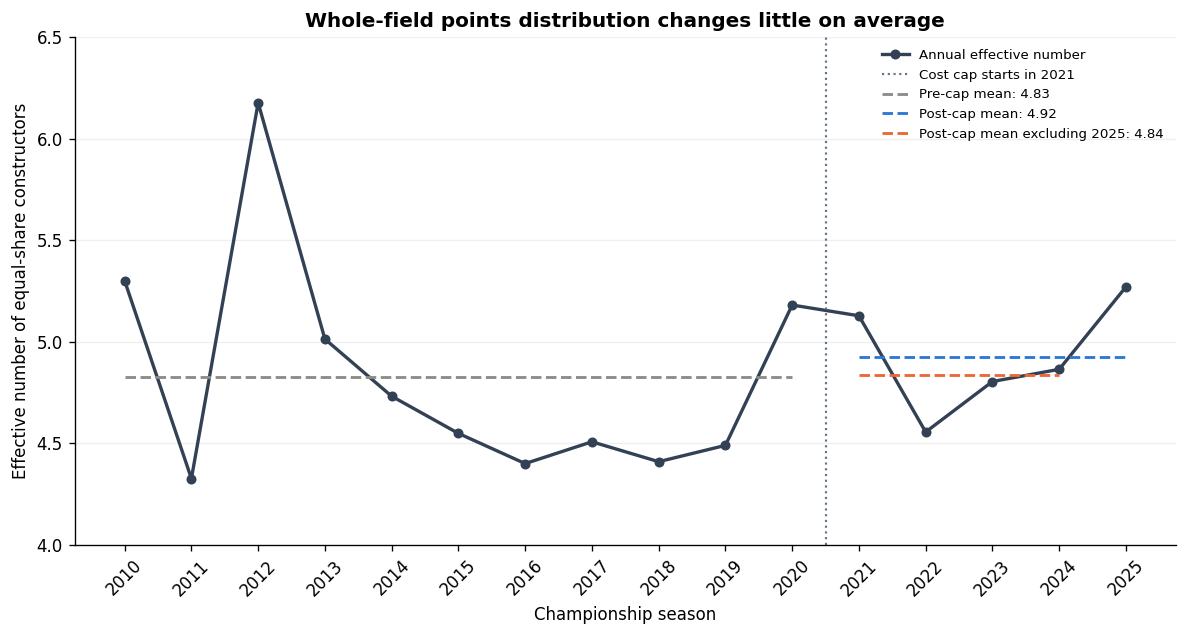

,window,seasons,mean_effective_teams,difference_from_pre
0,2010–2020,11,4.826,0.000
1,2021–2025,5,4.925,0.099
2,2021–2024,4,4.838,0.012


,year,hhi,actual_constructor_ids,effective_teams
0,2010,0.189,12,5.300
1,2011,0.231,12,4.327
2,2012,0.162,12,6.176
3,2013,0.199,11,5.013
4,2014,0.211,11,4.732
5,2015,0.220,10,4.549
6,2016,0.227,11,4.401
7,2017,0.222,10,4.508
8,2018,0.227,10,4.410
9,2019,0.223,10,4.490


**Takeaway.** The effective number rose from 4.83 to 4.92, a change of +0.10 calculated before rounding. Without 2025 the post-cap average was 4.84, indicating little overall change in points evenness.

In [24]:
# Chart 15: Group the documented constructor-year entries before squaring; the 2018 companion adds zero.
hhi_source = standings[["year", "constructorId", "points_share"]].copy()
assert hhi_source.notna().all().all()
assert hhi_source["year"].between(START_YEAR, END_YEAR).all()
hhi_source = hhi_source.groupby(["year", "constructorId"], as_index=False)["points_share"].sum()
assert set(hhi_source["year"]) == set(range(START_YEAR, END_YEAR + 1))
assert np.allclose(hhi_source.groupby("year")["points_share"].sum(), 100, rtol=0, atol=1e-9)
hhi_source["squared_fractional_share"] = (hhi_source["points_share"] / 100) ** 2
hhi_yearly = hhi_source.groupby("year").agg(
    hhi=("squared_fractional_share", "sum"),
    actual_constructor_ids=("constructorId", "nunique"),
).reset_index()
hhi_yearly["effective_teams"] = 1 / hhi_yearly["hhi"]
assert hhi_yearly["effective_teams"].ge(1).all()
assert (hhi_yearly["effective_teams"] <= hhi_yearly["actual_constructor_ids"] + 1e-9).all()
effective_pre = hhi_yearly.loc[hhi_yearly.year.lt(2021), "effective_teams"].mean()
effective_post = hhi_yearly.loc[hhi_yearly.year.ge(2021), "effective_teams"].mean()
effective_post_no_2025 = hhi_yearly.loc[hhi_yearly.year.between(2021, 2024), "effective_teams"].mean()
effective_change = effective_post - effective_pre  # Subtract before rounding.

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.plot(hhi_yearly["year"], hhi_yearly["effective_teams"], color="#334155", linewidth=2,
        marker="o", markersize=5, label="Annual effective number")
ax.axvline(2020.5, color="#64748b", linestyle=":", linewidth=1.3, label="Cost cap starts in 2021")
for value, start, end, color, label in [
    (effective_pre, 2010, 2020, ERA_COLORS[ERA_PRE], "Pre-cap mean"),
    (effective_post, 2021, 2025, ERA_COLORS[ERA_POST], "Post-cap mean"),
    (effective_post_no_2025, 2021, 2024, "#eb6834", "Post-cap mean excluding 2025")]:
    ax.hlines(value, start, end, colors=color, linestyles="--", linewidth=1.7,
              label=f"{label}: {value:.2f}")
ax.set(title="Whole-field points distribution changes little on average", xlabel="Championship season",
       ylabel="Effective number of equal-share constructors", ylim=(4.0, 6.5))
ax.set_xticks(range(2010, 2026))
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()
effective_summary = pd.DataFrame({
    "window": ["2010–2020", "2021–2025", "2021–2024"], "seasons": [11, 5, 4],
    "mean_effective_teams": [effective_pre, effective_post, effective_post_no_2025],
    "difference_from_pre": [0, effective_change, effective_post_no_2025-effective_pre],
})
display(effective_summary.round(3))
display(hhi_yearly.round(3))


display(Markdown(f"""**Takeaway.** The effective number rose from {effective_pre:.2f} to {effective_post:.2f}, a change of {effective_change:+.2f} calculated before rounding. Without 2025 the post-cap average was {effective_post_no_2025:.2f}, indicating little overall change in points evenness."""))

**Section takeaway.** Whole-field evenness changed little, especially without 2025. This gives a different perspective from the fall in top-two share.

## 9. Findings and Stakeholder Actions

**What decisions can stakeholders take from these results?**

The table collects the main results. The final checks confirm season coverage, share totals, and the direction of the CR2 test before the recommendations below.

In [25]:
assert len(metrics) == 16 and metrics["year"].between(2010, 2025).all()
assert len(pre_cr2) == 11 and len(post_cr2) == 5
assert np.sign(welch_result.statistic) == np.sign(mean_difference)
assert standings["points"].notna().all() and standings["points_share"].notna().all()
assert np.allclose(standings.groupby("year")["points_share"].sum(), 100, rtol=0, atol=1e-9)
findings = pd.DataFrame([
    {"measure": "CR2 share (%)", "pre": pre_mean, "post": post_mean, "post_excluding_2025": metrics.loc[metrics.year.between(2021, 2024), "cr2_pct"].mean()},
    {"measure": "P4–P7 share (%)", "pre": era_summary.loc[0, "midfield_mean_pct"], "post": era_summary.loc[1, "midfield_mean_pct"], "post_excluding_2025": metrics.loc[metrics.year.between(2021, 2024), "midfield_p4_p7_pct"].mean()},
    {"measure": "Big Three share (%)", "pre": pre_b3.mean(), "post": post_b3.mean(), "post_excluding_2025": post_b3_ex2025.mean()},
    {"measure": "Podium places outside Big Three (%)", "pre": podium_pre, "post": podium_post, "post_excluding_2025": podium_post_no_2025},
    {"measure": "Effective equal-share constructors", "pre": effective_pre, "post": effective_post, "post_excluding_2025": effective_post_no_2025},
])
findings["post_minus_pre"] = findings["post"] - findings["pre"]
display(findings.round(3))
print(f"Original CR2 comparison: difference {mean_difference:+.2f} percentage points; "
      f"Welch t={welch_result.statistic:.3f}, two-sided p={welch_result.pvalue:.3f}.")
print(f"Integrity checks passed: 16 seasons, no null points or shares, sign consistency, and annual shares summing to 100%. "
      f"Largest rounding residual: {share_check['difference_from_100_pp'].abs().max():.2e} percentage points.")

,measure,pre,post,post_excluding_2025,post_minus_pre
0,CR2 share (%),54.722,52.140,52.846,-2.581
1,P4–P7 share (%),24.710,26.158,25.917,1.448
2,Big Three share (%),67.512,65.820,69.793,-1.692
3,Podium places outside Big Three (%),18.510,26.035,19.350,7.525
4,Effective equal-share constructors,4.826,4.925,4.838,0.099


Original CR2 comparison: difference -2.58 percentage points; Welch t=-1.215, two-sided p=0.245.
Integrity checks passed: 16 seasons, no null points or shares, sign consistency, and annual shares summing to 100%. Largest rounding residual: 1.42e-14 percentage points.


1. **FIA and F1: review several balance measures before changing financial rules.** The original CR2 decline is 2.58 percentage points (p = 0.245), and the Big Three comparison reverses without 2025 (Charts 4–5). Include both baselines, results with and without the latest season, and whole-field measures in the review. **High impact / Moderate effort.**

2. **Constructors: set targets against relevant improving peers.** McLaren gains 7.48 percentage points of average share, while Williams and Alpine lose 2.70 and 2.05 (Charts 6–9). Use the team paths to select benchmarks and development milestones, together with internal evidence on resources and performance decisions. **Medium impact / Moderate effort.**

3. **Sponsors: consider emerging contenders and agree performance conditions.** Podium-reaching teams rise from 5.18 to 6.00 per season, but outside-Big-Three podium share averages 19.35% without 2025, compared with 26.04% with it (Charts 12–14). Assess individual teams over several seasons and add audience and exposure data before pricing a deal. **High impact / Low effort for shortlisting; contract effort varies.**

4. **F1 commercial teams and broadcasters: prepare for both close and dominant seasons.** Post-cap title margins range from 0.53 percentage points in 2024 to 18.35 in 2023 (Chart 11). Build coverage around the competition that develops, without promising a close title fight every year. **Medium impact / Low effort.**

**Takeaway.** The results inform rule reviews, team benchmarks, and commercial shortlists. They do not show which spending or sponsorship decisions will deliver a return.

## 10. Conclusion and Next Steps

**What does the full analysis say about competitive balance?**

The top two took a slightly smaller share after 2021, and P4–P7 gained a little. The result becomes less straightforward when we inspect the years and teams: CR2 depends on the baseline, the Big Three decline depends heavily on 2025, and McLaren and Red Bull account for the largest gains among continuing lineages.

More teams reached podiums, but almost the same number won races. Whole-field effective teams moved only from 4.83 to 4.92. The evidence shows a redistribution of success, with limited evidence of broad, lasting parity.

**Actions.** Use the joint regulatory review, team benchmarks, and sponsorship assessments in Section 9.

**Risks and limitations.** Five post-cap seasons are a small sample. The 2022 car redesign, aerodynamic testing restrictions, drivers, investment histories, scoring changes, and calendar composition also affect results. Points shares account for different season totals without removing these influences. Consecutive seasons may be related, and the supporting tests are exploratory and unadjusted for multiple comparisons. A p-value above 0.05 is inconclusive; a lower one does not establish a policy effect. Grid size and participation histories also affect some measures. Points are not budgets, car speed, audience exposure, or financial returns.

**Next steps.** The FIA can add completed seasons and comparable public spending disclosures to its next review. Commercial partners can combine team results with audience and exposure data before valuing a deal. **High impact / Moderate effort.**

**Takeaway.** Some outcomes improved in this sample. We cannot isolate how much of the change came from the cost cap.

## 11. Challenges and How We Handled Them

**Which data problems required judgment?**

- **Names and participation.** We kept source IDs, added chronology-checked lineage labels, left absent seasons blank, and reported participation counts. A continuing lineage does not imply unchanged ownership or investment.
- **Force India, 2018.** The source has one ranked 52-point row and one unranked zero-point companion. We checked and retained both, restoring no forfeited points.
- **Missing positions and joins.** We audited nulls, used official ranks, and required unique lookup keys, complete matches, and unchanged row counts.
- **Calendar and scoring changes.** We calculated within-season shares and kept Grand Prix wins and podiums separate from sprints.
- **Small samples and influential years.** We retained the original comparison, showed the alternative alongside it, and calculated leave-one-season-out results.
- **Reproducibility.** We pinned the release and checked its digest. Tables and chart takeaways use the calculated variables; the download cell records retrieval time.

**Takeaway.** These choices preserve the source records and explain what the comparisons include and leave out.

## 12. References

- F1DB contributors. [Database and documentation](https://github.com/f1db/f1db), [release v2026.15.1](https://github.com/f1db/f1db/releases/tag/v2026.15.1), and [CC BY 4.0 license](https://github.com/f1db/f1db/blob/main/LICENSE). Tables: constructors, constructor standings, seasons, races, Grand Prix results, and constructors chronology.
- Formula 1. [The 2021 rules and regulation changes](https://www.formula1.com/en/latest/article/aero-tweaks-new-tyres-and-the-cost-cap-the-2021-f1-rules-and-regulation.r1cq36aI6bvzMeZtiFru3). Cost-cap baselines and ATR.
- Formula 1. [Seven key rule changes for 2022](https://www.formula1.com/en/latest/article/7-key-rule-changes-for-the-2022-season.2E7JH9MywymU8xxw6r5yDS). Aerodynamic redesign and overlapping rules.
- Formula 1. [Racing Point Force India entry](https://www.formula1.com/en/latest/article/fia-approve-racing-point-force-india-f1-entry.3BsgxEhqbYeUqec40OaSEw). The 2018 entry change and forfeited points.
- Formula 1. [McLaren year by year](https://www.formula1.com/en/information/mclaren-year-by-year.6Gj22qyOorq5dpniarY3rP). The 2024 and 2025 constructors' titles.
- Formula 1. [2025 rule changes](https://www.formula1.com/en/latest/article/7-rule-changes-you-need-to-know-for-the-2025-f1-season.pgdSMDnDyv1aJUgtcKPp6). Removal of the fastest-lap point.
- SciPy developers. [`scipy.stats.ttest_ind`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html). Welch's test and sample order.
- U.S. Department of Justice. [Herfindahl–Hirschman Index](https://www.justice.gov/atr/herfindahl-hirschman-index). Sum-of-squared-shares definition; the notebook derives and illustrates its reciprocal.

## 13. Generative AI Disclosure

This is a four-person team project, and the main work was carried out by our team. We developed the research question, decided which analyses to perform, worked through the data, and interpreted the results. We used AI tools at different stages to help with specific technical challenges and improve how we explained and presented our work.

- **Planning.** We used Gemini Deep Research to brainstorm the initial research question and possible metrics. GPT and Claude helped us organize our ideas, structure the analysis, and put together a work plan. The final decisions about what to analyze and how to approach the project were made by our team.
- **Code.** Our team worked on the data processing, analysis, and charts, using AI assistance when we needed help with more complex code, syntax, or ways to make parts of the notebook more efficient. Claude helped with starter code for some additional charts and lineage mapping. ChatGPT/Codex helped us refine and integrate parts of the data download, cleaning, joins, validation checks, statistical comparisons, and calculated measures. We reviewed and adapted these suggestions to fit our analysis. Our team also proposed additional measures for some of the charts and worked on incorporating them into the notebook.
- **Writing and review.** We developed the report based on our analysis and findings, with help from Gemini, Claude, and ChatGPT to improve sentence structure, polish the wording, and make certain explanations clearer. These tools also helped us organize and refine the executive summary, findings, recommendations, conclusion, challenges, references, and this disclosure. Claude and Gemini reviewed the final code and notebook, and ProfAI provided an earlier review checklist.
- **Verification.** Our team restarted, ran, and checked an earlier version of the notebook in Colab. After revising the written sections, we reran the updated notebook in a fresh local Python kernel using the same pinned release. Automated checks covered missing data points, joins, season coverage, the Force India exception, official ranking groups, share totals, and test direction. We also checked the numerical outputs and saved charts against the report.

We are responsible for understanding the work, explaining the code and analytical choices, interpreting the results, and checking the final submission.

**Takeaway.** AI tools helped us work through some technical challenges and improve the presentation of our findings, but the project decisions, analysis, and final conclusions remain our team's responsibility.